# What each systematic uncertainty does

Four views of the systematic uncertainties of the signal, from the outputs of
`03_limits.ipynb` and the same campaign:

1. **Up and down templates.** For one signal point per final state and every entry of
   `systematics.yaml`: the signal $m_{LJLJ}$ distribution in regions A to D with its up and
   down variations, and their ratio to the nominal. They show whether a systematic changes
   only the normalisation, so that one log-normal number per region (what the cards use) is
   enough, or also the shape; whether it is symmetric; and whether the variation stands out
   from the statistical fluctuations of the simulated signal.
2. **Size across the signal grid.** The size in region A of every systematic that varies
   from point to point, and of the statistical uncertainty of the simulated signal, as maps
   over the bound state mass, the dark photon mass and $L_{xy}$.
3. **Impacts.** For the same two points, the shift of the fitted $r$ when each nuisance
   moves by one standard deviation, on the Asimov dataset with the signal injected at the
   point's expected limit (`sidm/scripts/run_combine_impacts.py`). Without an injected
   signal, a nuisance that acts on the signal alone has no impact at all.
4. **Limit breakdown.** The expected limits of the limit grid with each systematic left out
   in turn, all of them left out, and every constrained nuisance fixed (statistics only),
   as the change each makes to the limit with every systematic.

**Rerun after `03_limits.ipynb`** whenever an entry is added to `systematics.yaml`. This
notebook follows the registry and reads the cards, shapes, systematics and limits that
03_limits wrote to EOS; it stops if those are not from the current `systematics.yaml`.

**Blinded**, as 03_limits: the cards take regions B, C and D from data, region A of data is
never read, and every fit is to the Asimov dataset; sections 3 and 4 use the cards of the
integrated estimate (`systematics_study.LIMITS_METHOD`), the likelihood of the AN's limits.
The figures and fit outputs go to EOS, under `effects/` in the output directory of 03_limits.
Combine works in a temporary directory, which is removed at the end.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture, for example after adding a systematic.

In [1]:
import json, os, shutil, sys, tempfile, warnings
from pathlib import Path
import fsspec
import numpy as np
from IPython.display import Image, display

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # sidm/studies/limit_plotting, put on the path by systematics_study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
dt = sysstudy.dt

CAMPAIGN = "systematics_v2"
dt.use_campaign(CAMPAIGN)
INPUT_DIR = sysstudy.eos_url(dt.CAMPAIGN.bkg_dir)   # the merged outputs of the campaign
LIMITS_DIR = f"{INPUT_DIR}{sysstudy.LIMITS_SUFFIX}"   # the data-driven outputs of 03_limits.ipynb
OUTPUT_DIR = f"{LIMITS_DIR}/effects"
REGISTRY = sysstudy.load_registry()
KAPPAS = sysstudy.limits_outputs(LIMITS_DIR, REGISTRY)["kappas"]   # stops if 03_limits needs a rerun
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(KAPPAS)
EXPECTED = {r["signal"]: r["exp"] for r in pt.as_rows(f"{LIMITS_DIR}/limits_with_{sysstudy.LIMITS_METHOD}/limits.csv")}
POINTS = {"SR_2mu2e": "2Mu2E_500GeV_1p2GeV_1p9mm", "SR_4mu": "4Mu_500GeV_1p2GeV_1p9mm"}   # sections 1 and 3
COMBINE = sysstudy.find_combine()
WORK = Path(tempfile.mkdtemp(prefix=f"effects_{CAMPAIGN}_"))   # removed at the end
FIGURES = WORK / "figures"


def show(path):
    """Display a figure that plot_tools saved"""
    display(Image(filename=str(path.with_suffix(".png"))))


print("inputs: ", INPUT_DIR, "and", LIMITS_DIR)
print("outputs:", OUTPUT_DIR)
print("Combine:", "on the PATH" if COMBINE and COMBINE.no_cmsenv else COMBINE.combine_cmssw if COMBINE else "not found")
print("systematics:", ", ".join(REGISTRY), f"| {len(LIMIT)} points on the limit grid")
print("points:", ", ".join(f"{p} (expected limit {EXPECTED[p]:.3g} fb)" for p in POINTS.values()))

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2 and root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits_data
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits_data/effects
Combine: /uscms_data/d3/scampbel/CMSSW_14_1_0_pre4
systematics: lumi_13TeV, CMS_pileup, CMS_l1_prefiring, CMS_jet_energy, CMS_eff_m_id, CMS_eff_e_reco, CMS_eff_g_pixelveto | 96 points on the limit grid
points: 2Mu2E_500GeV_1p2GeV_1p9mm (expected limit 5.37 fb), 4Mu_500GeV_1p2GeV_1p9mm (expected limit 6.01 fb)


## 1. Up and down templates

A `flat` entry scales the template, a `syst` entry is the Up and Down weight categories of
the campaign, and a `variant` (the jet energy) has an up variation only, which the cards
use symmetrically. The grey band in the ratio panels is the statistical uncertainty of the
nominal template. A variation re-weights or re-sorts the same simulated events, so it is
known better than this band, which shows the size of the fluctuations: a variation that
follows them from bin to bin is noise rather than a shape.

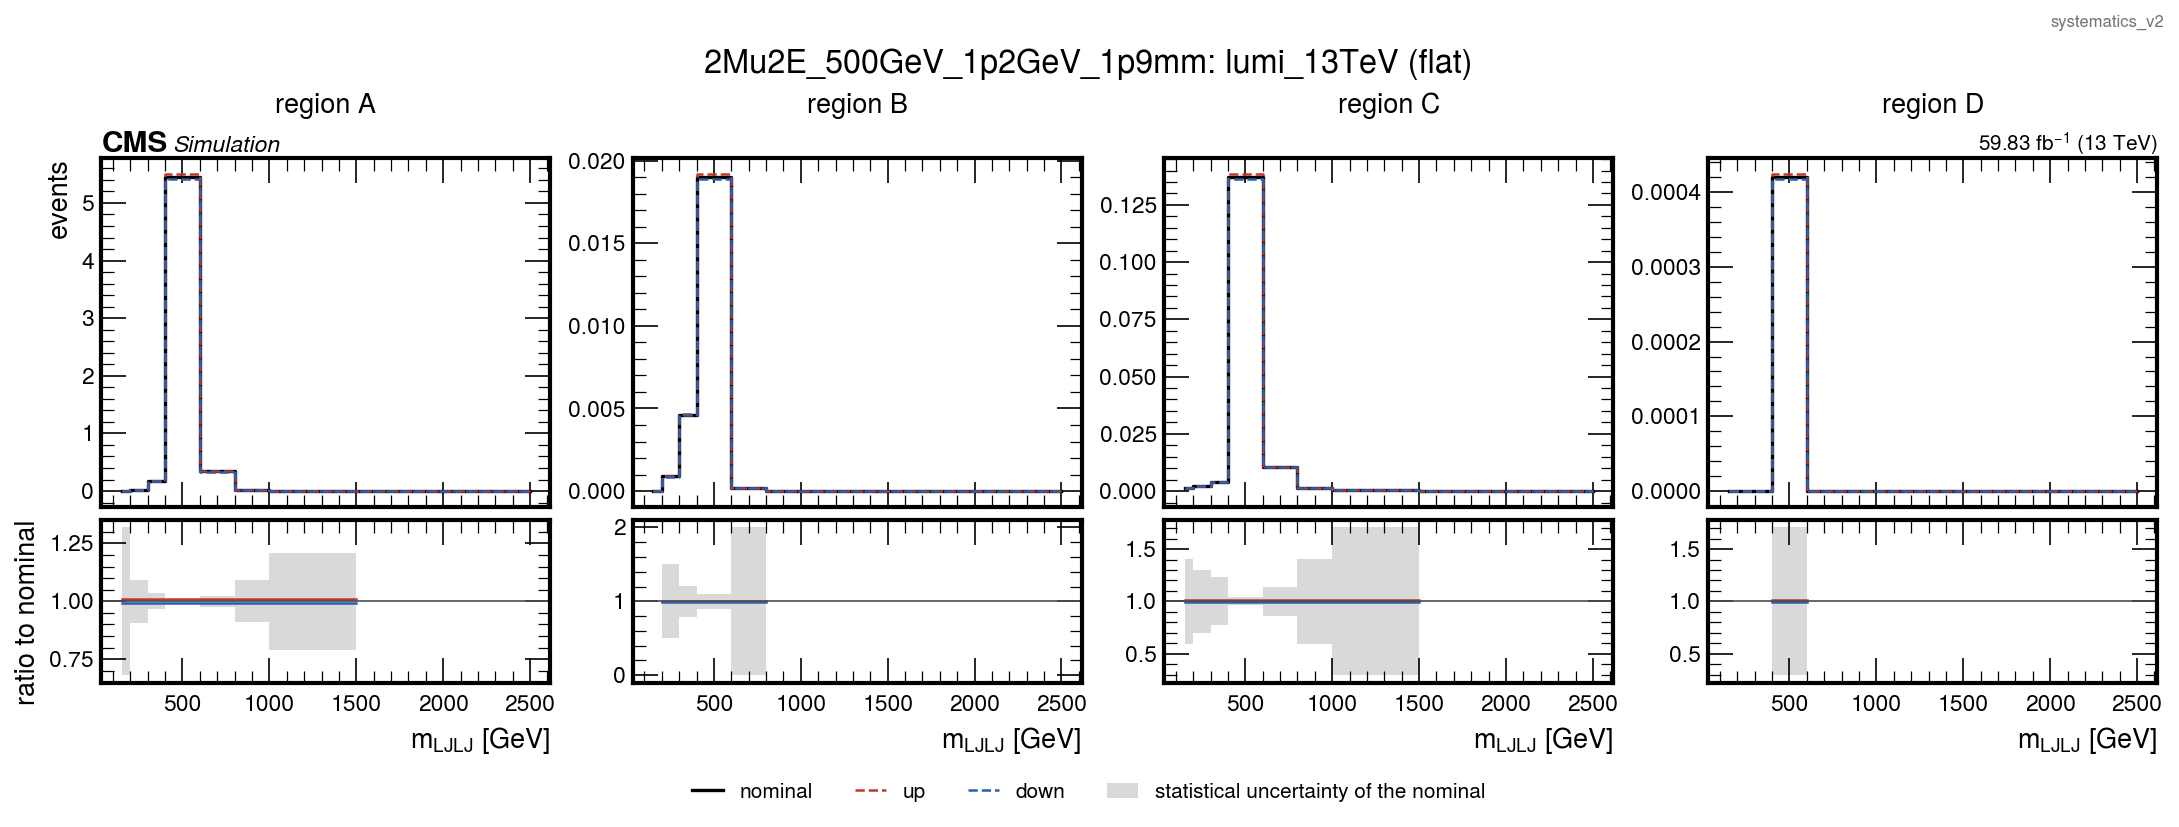

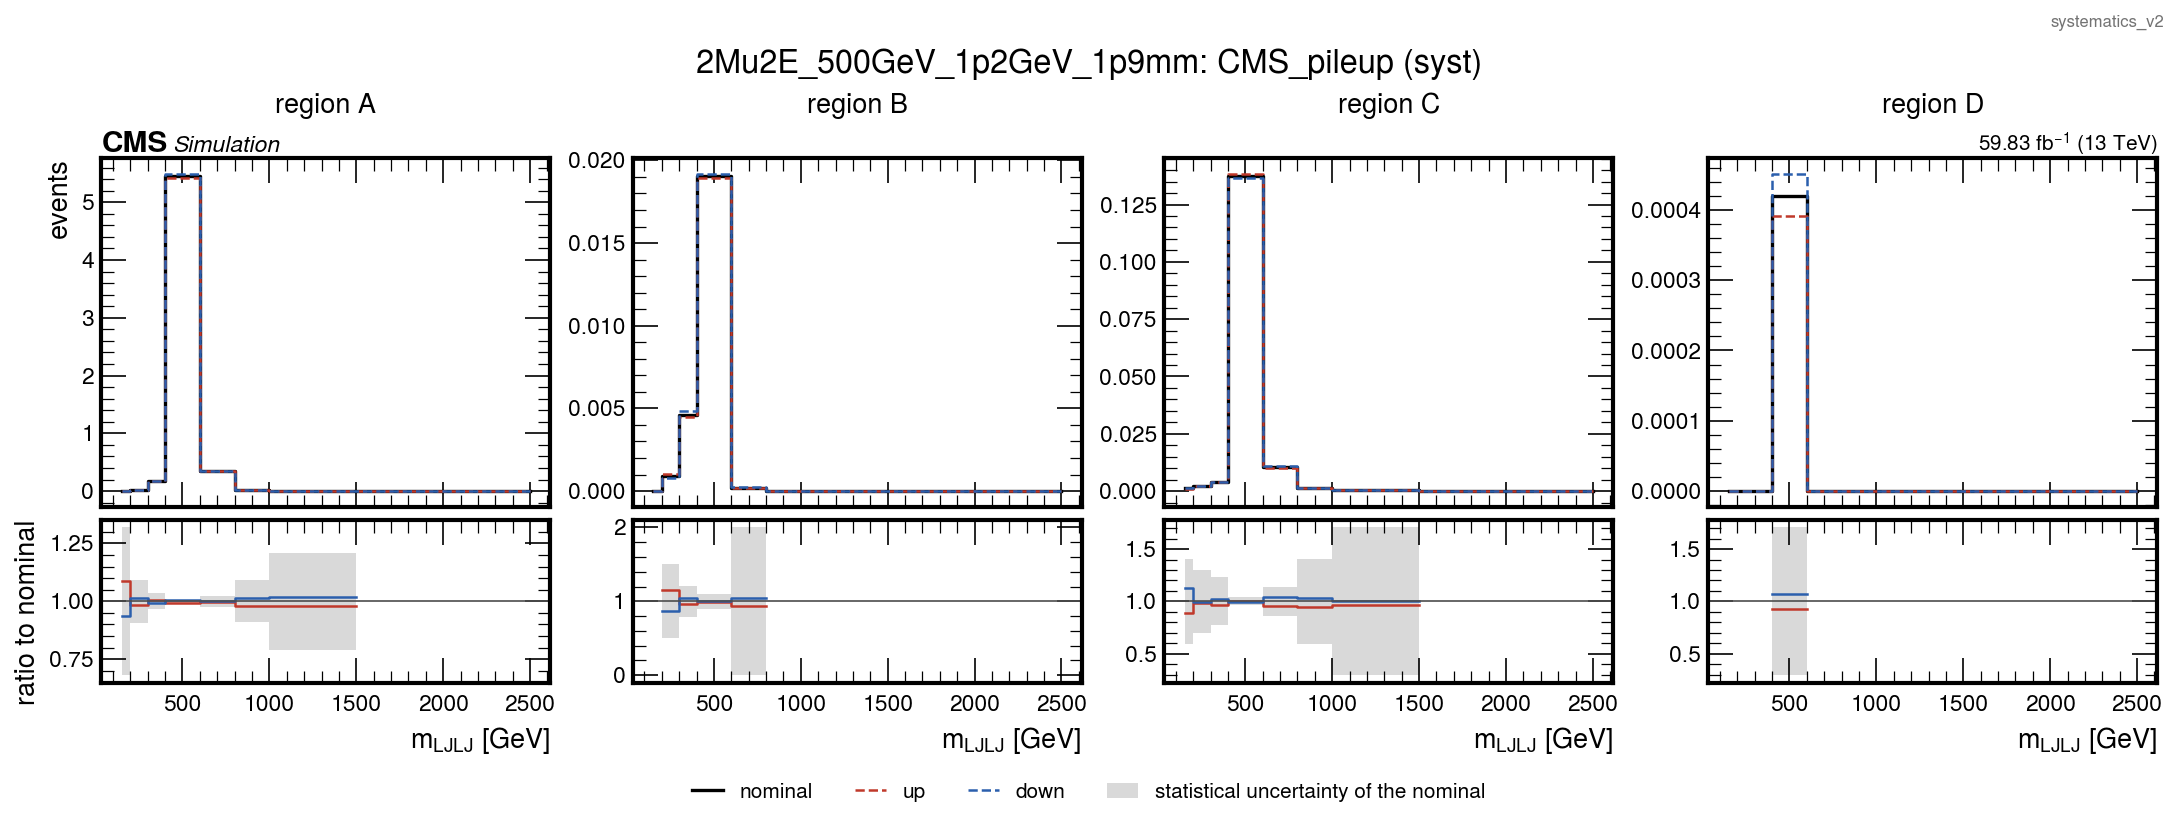

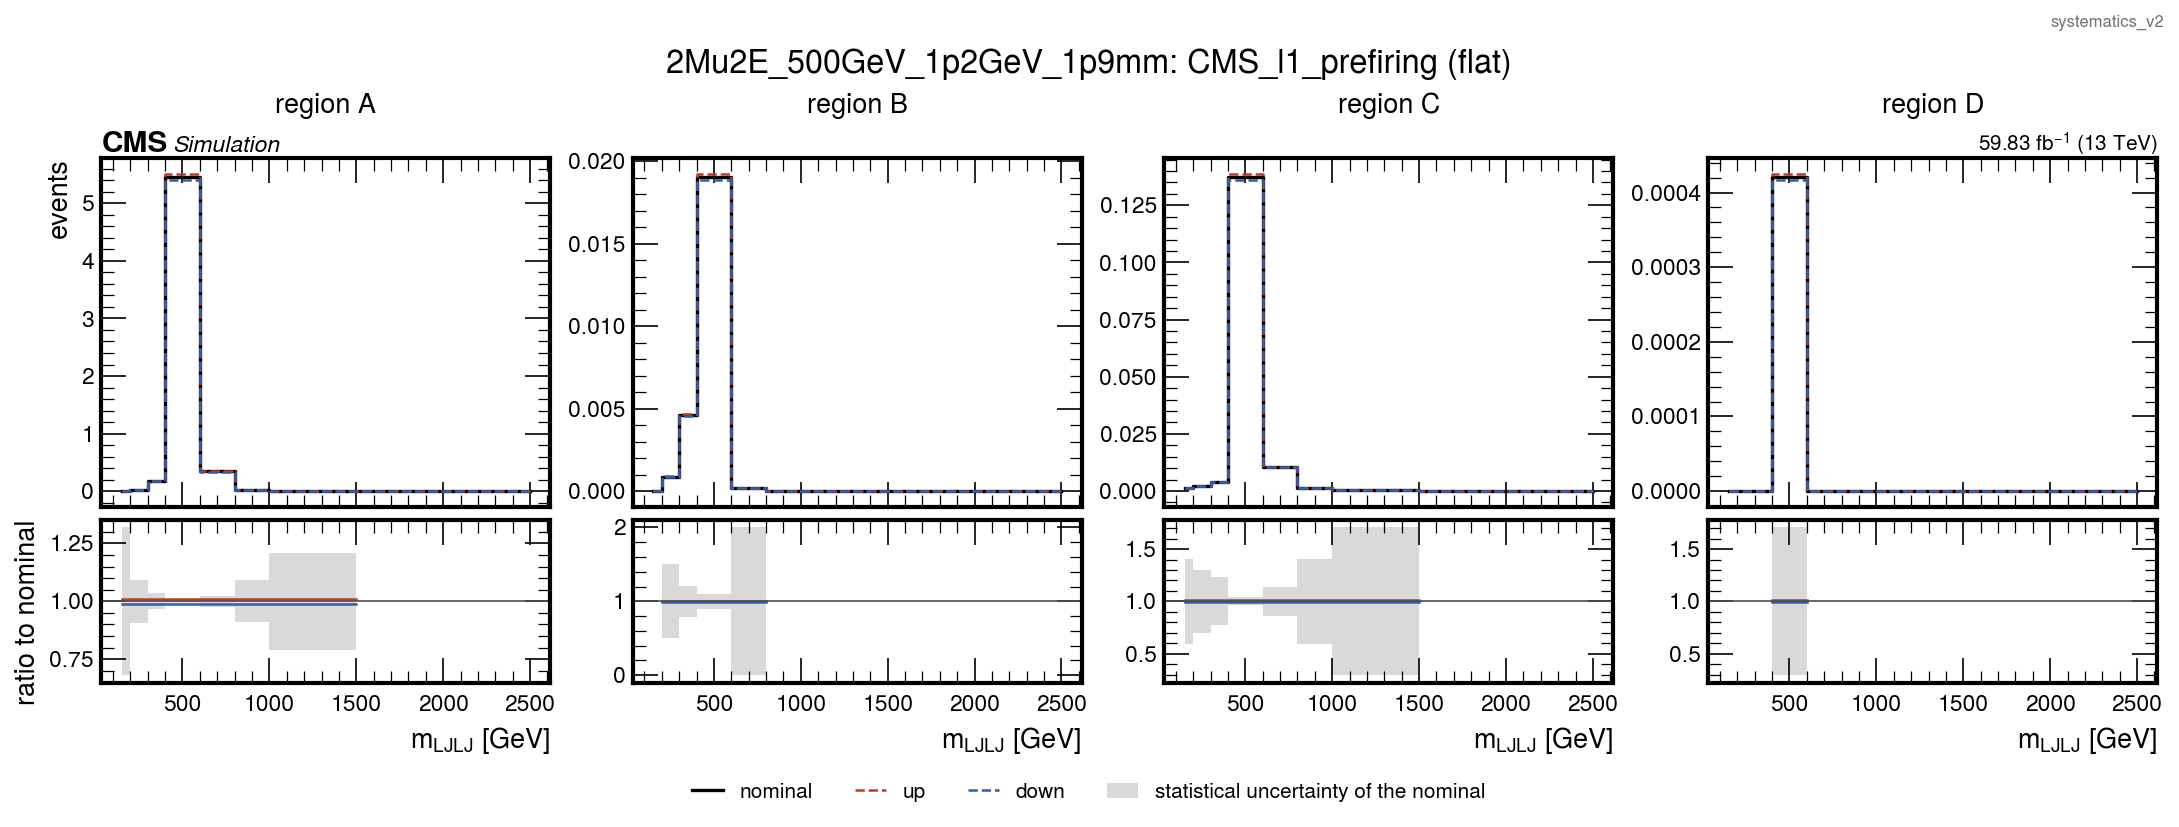

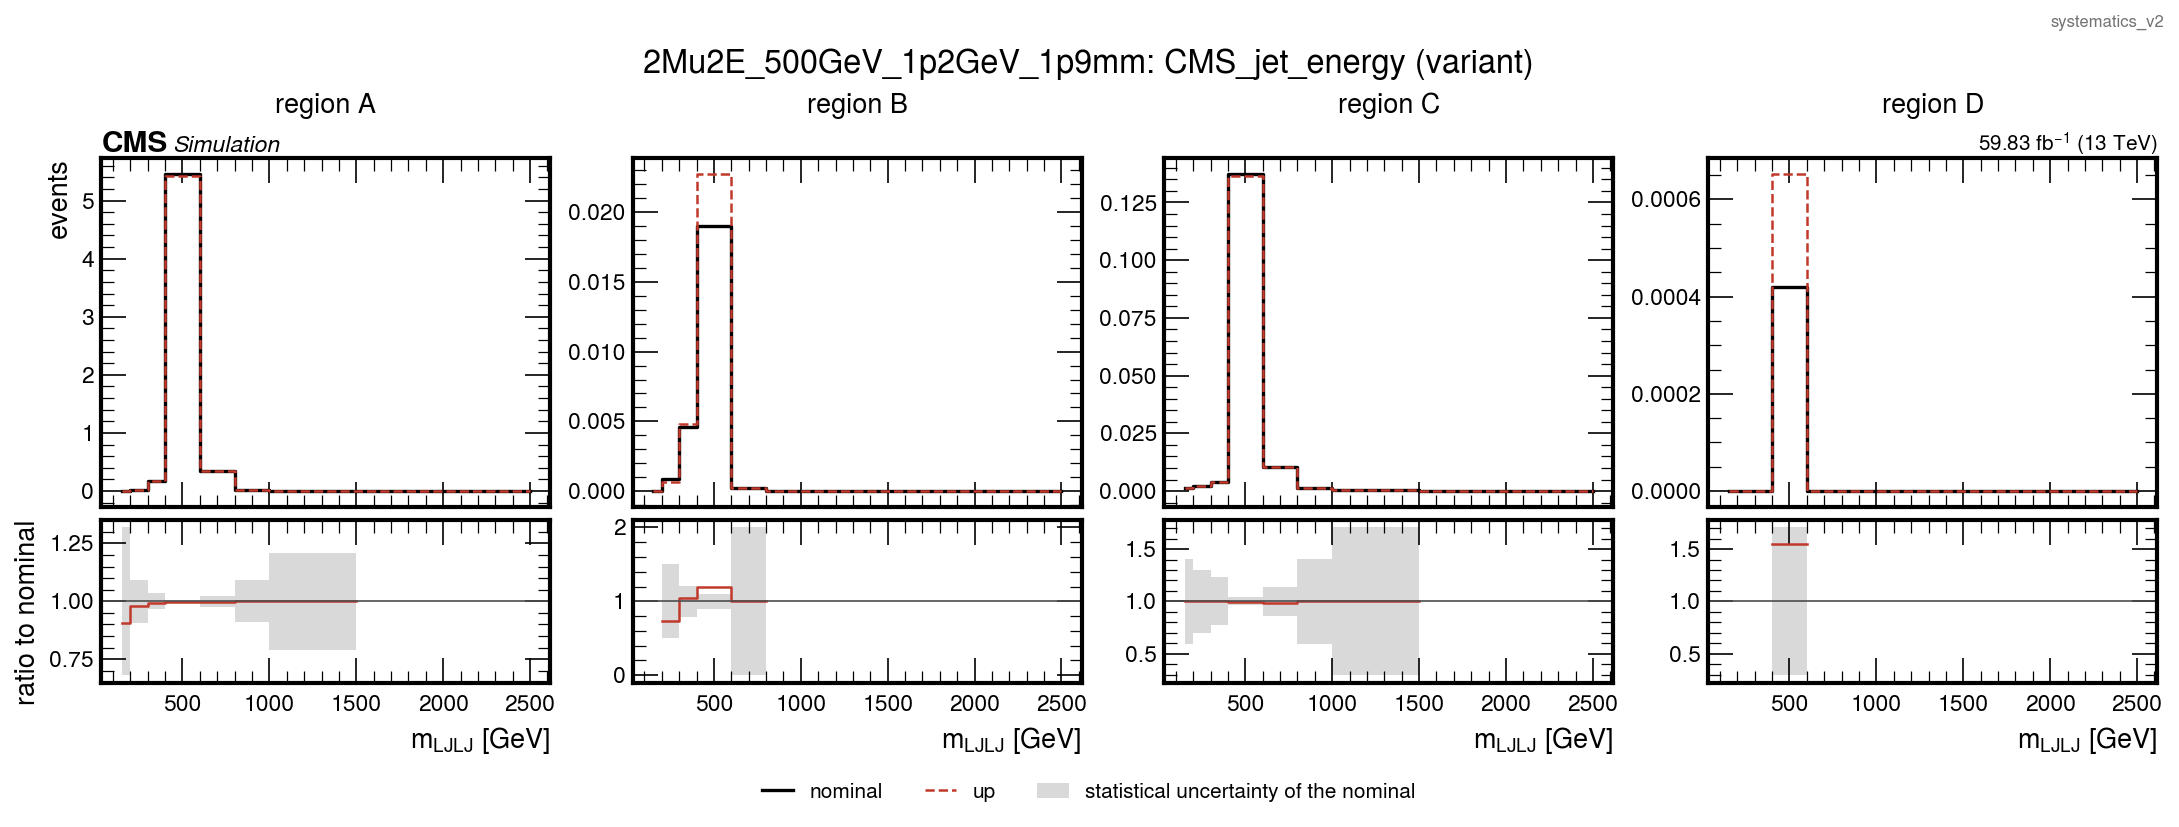

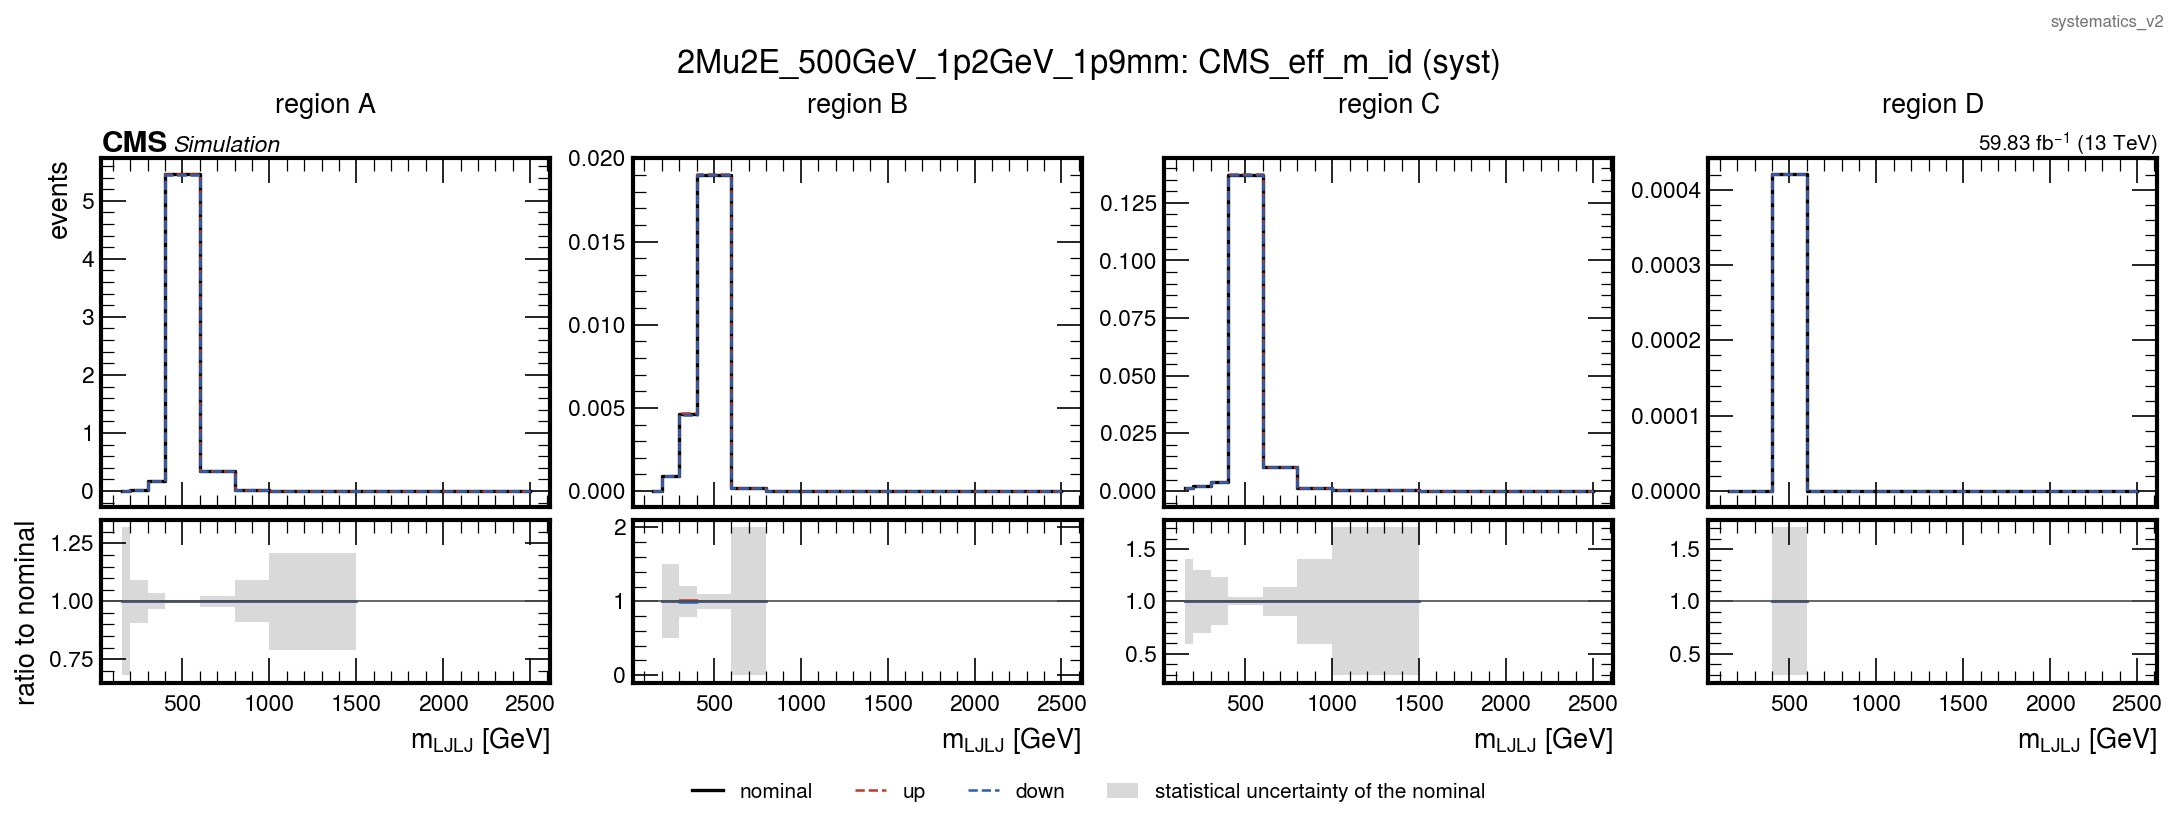

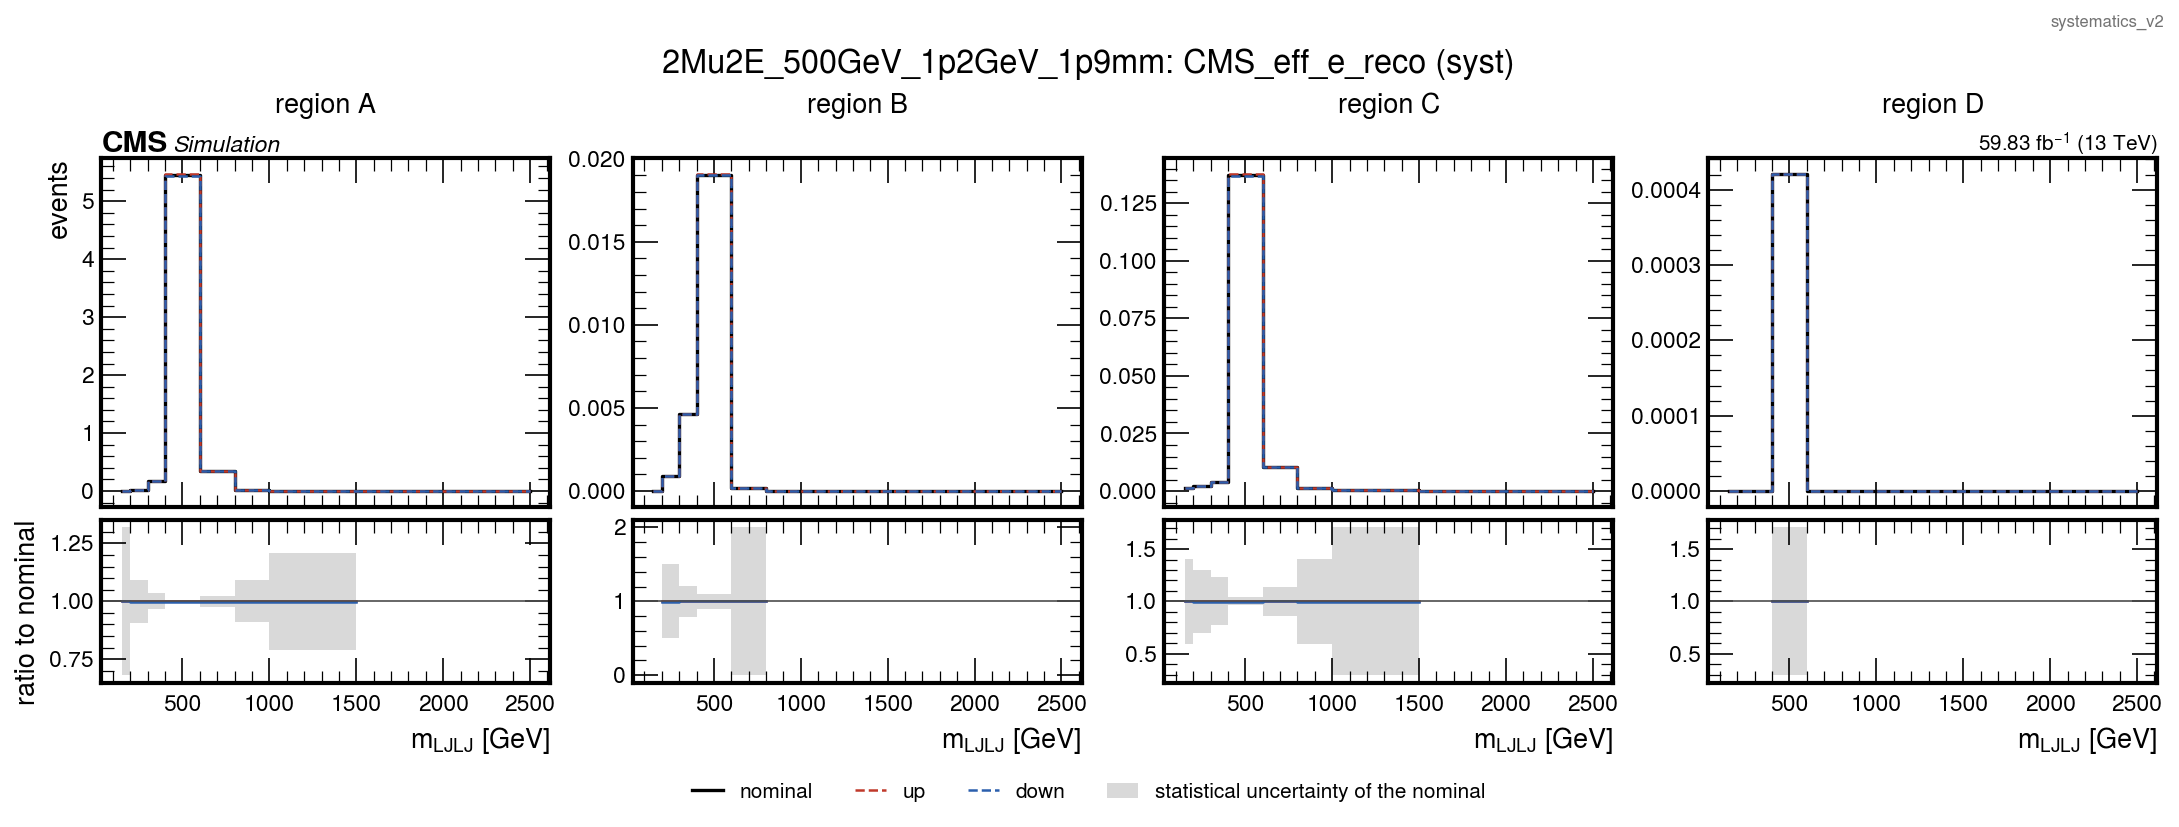

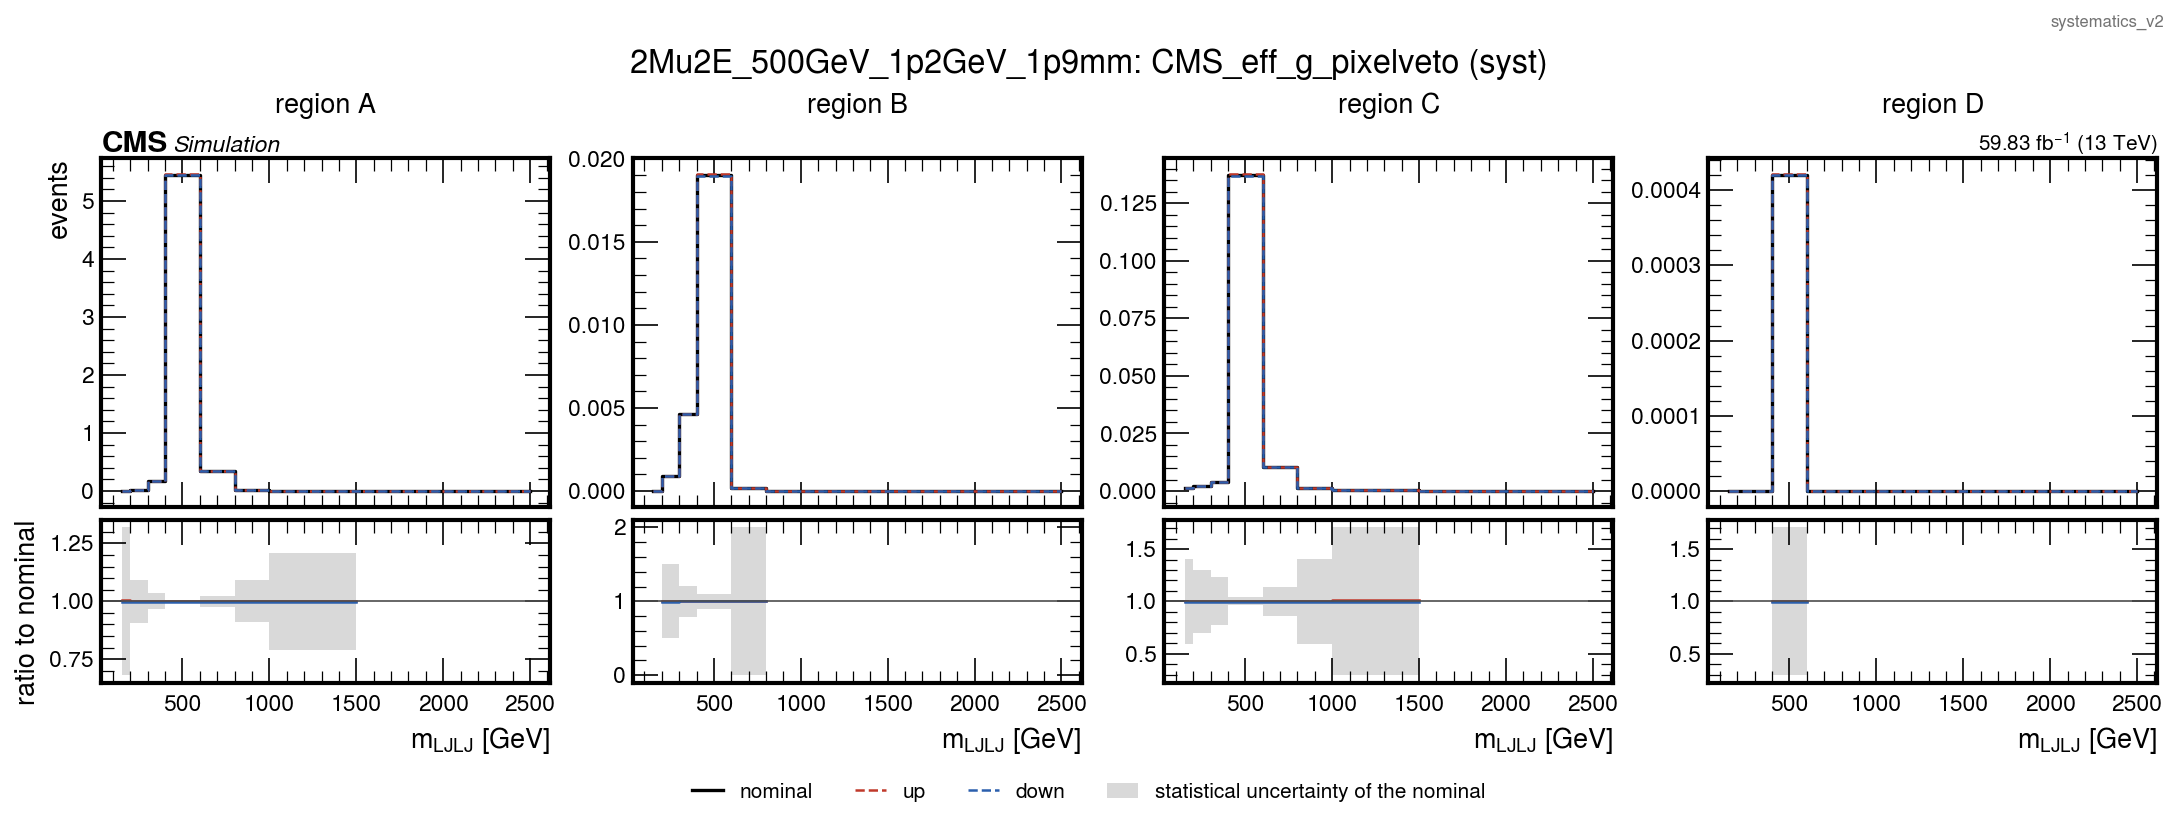

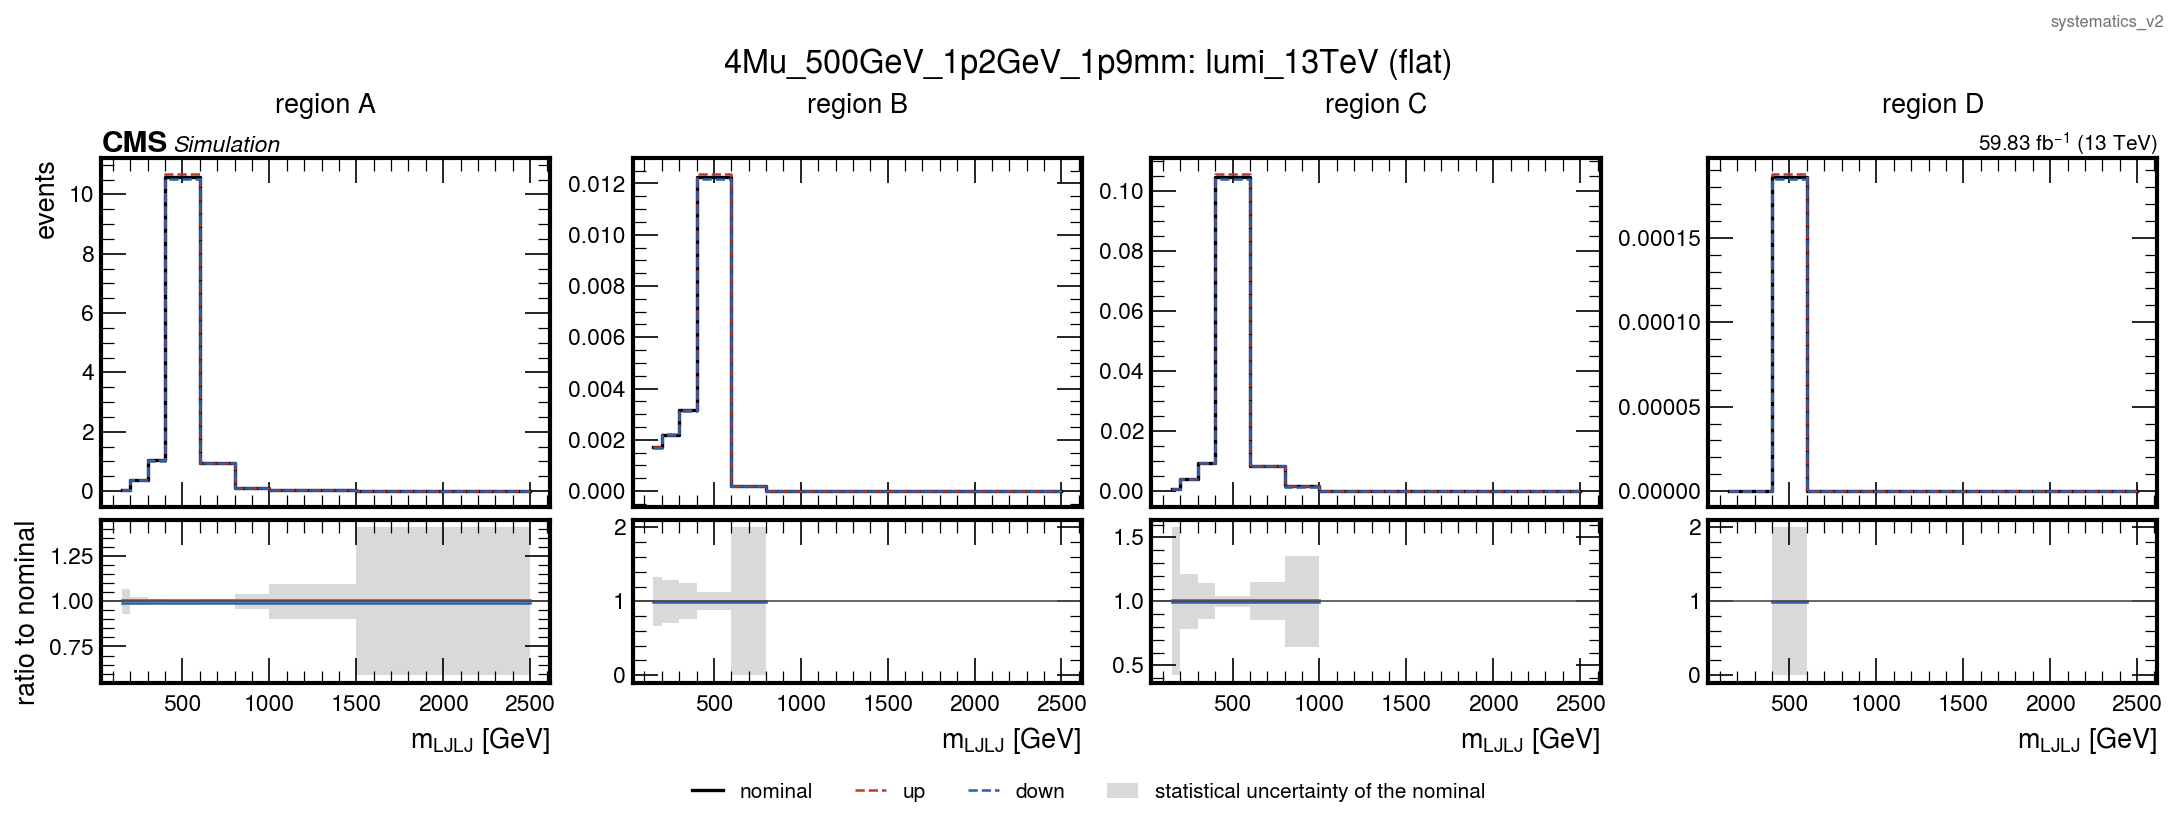

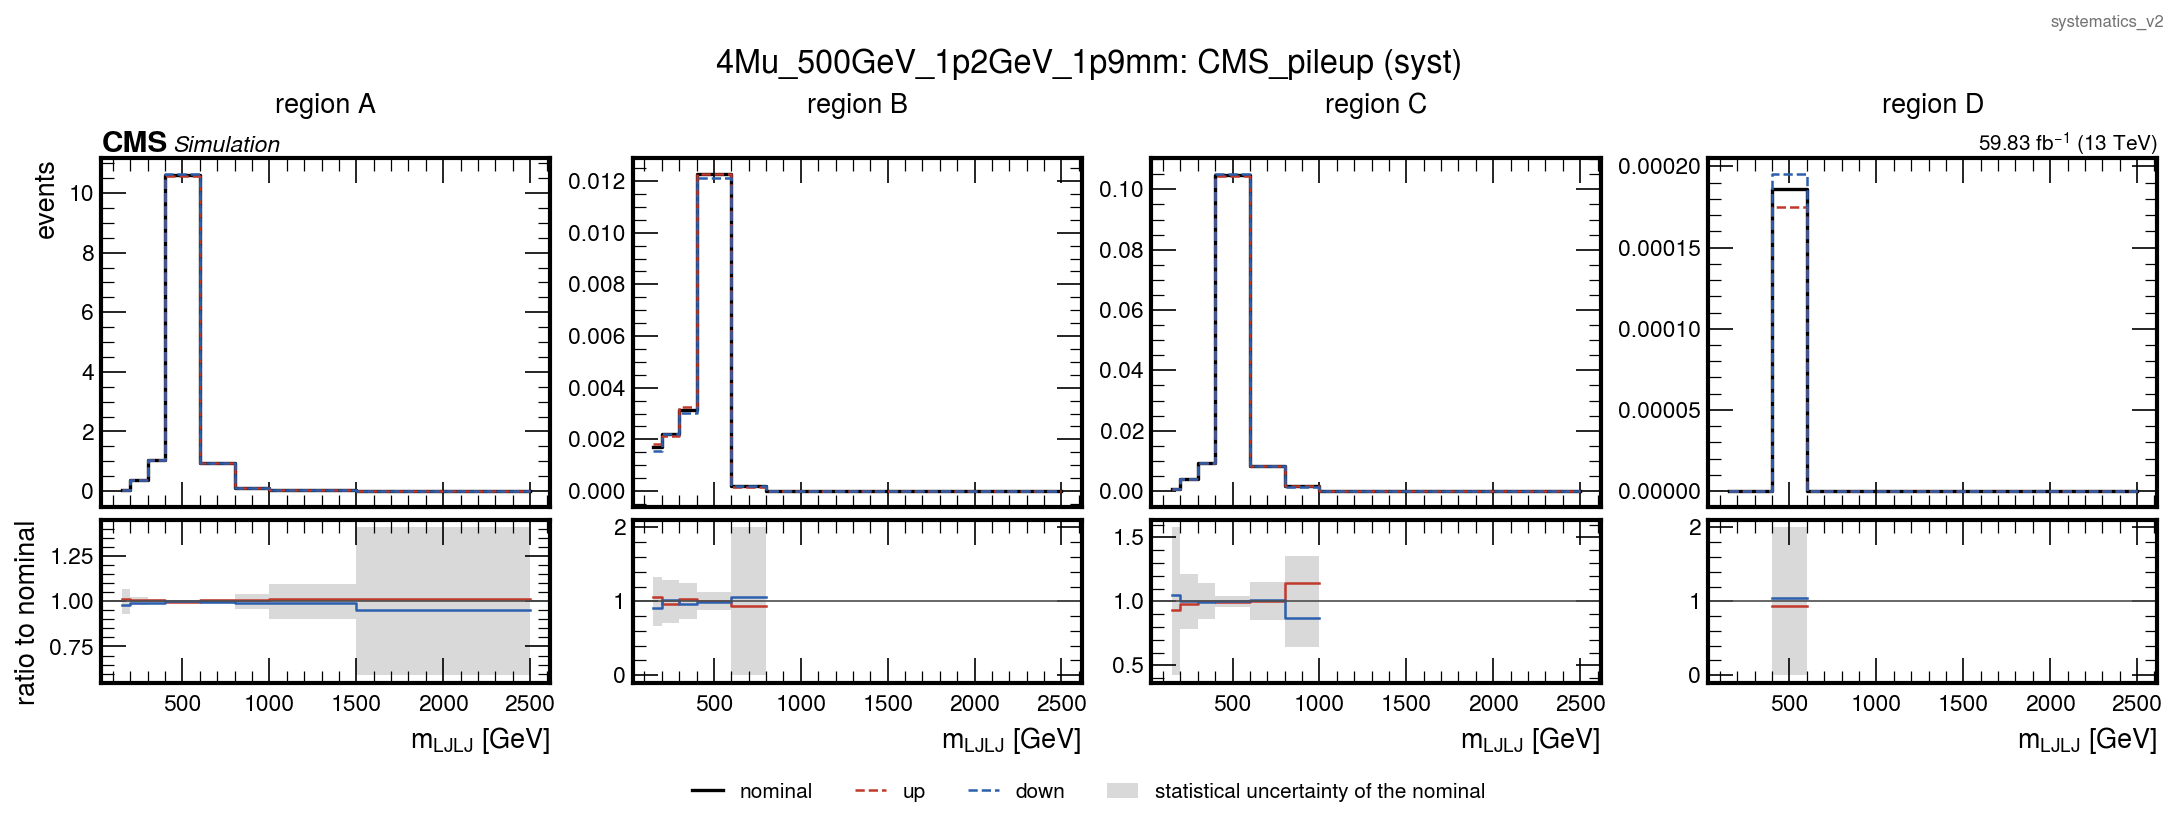

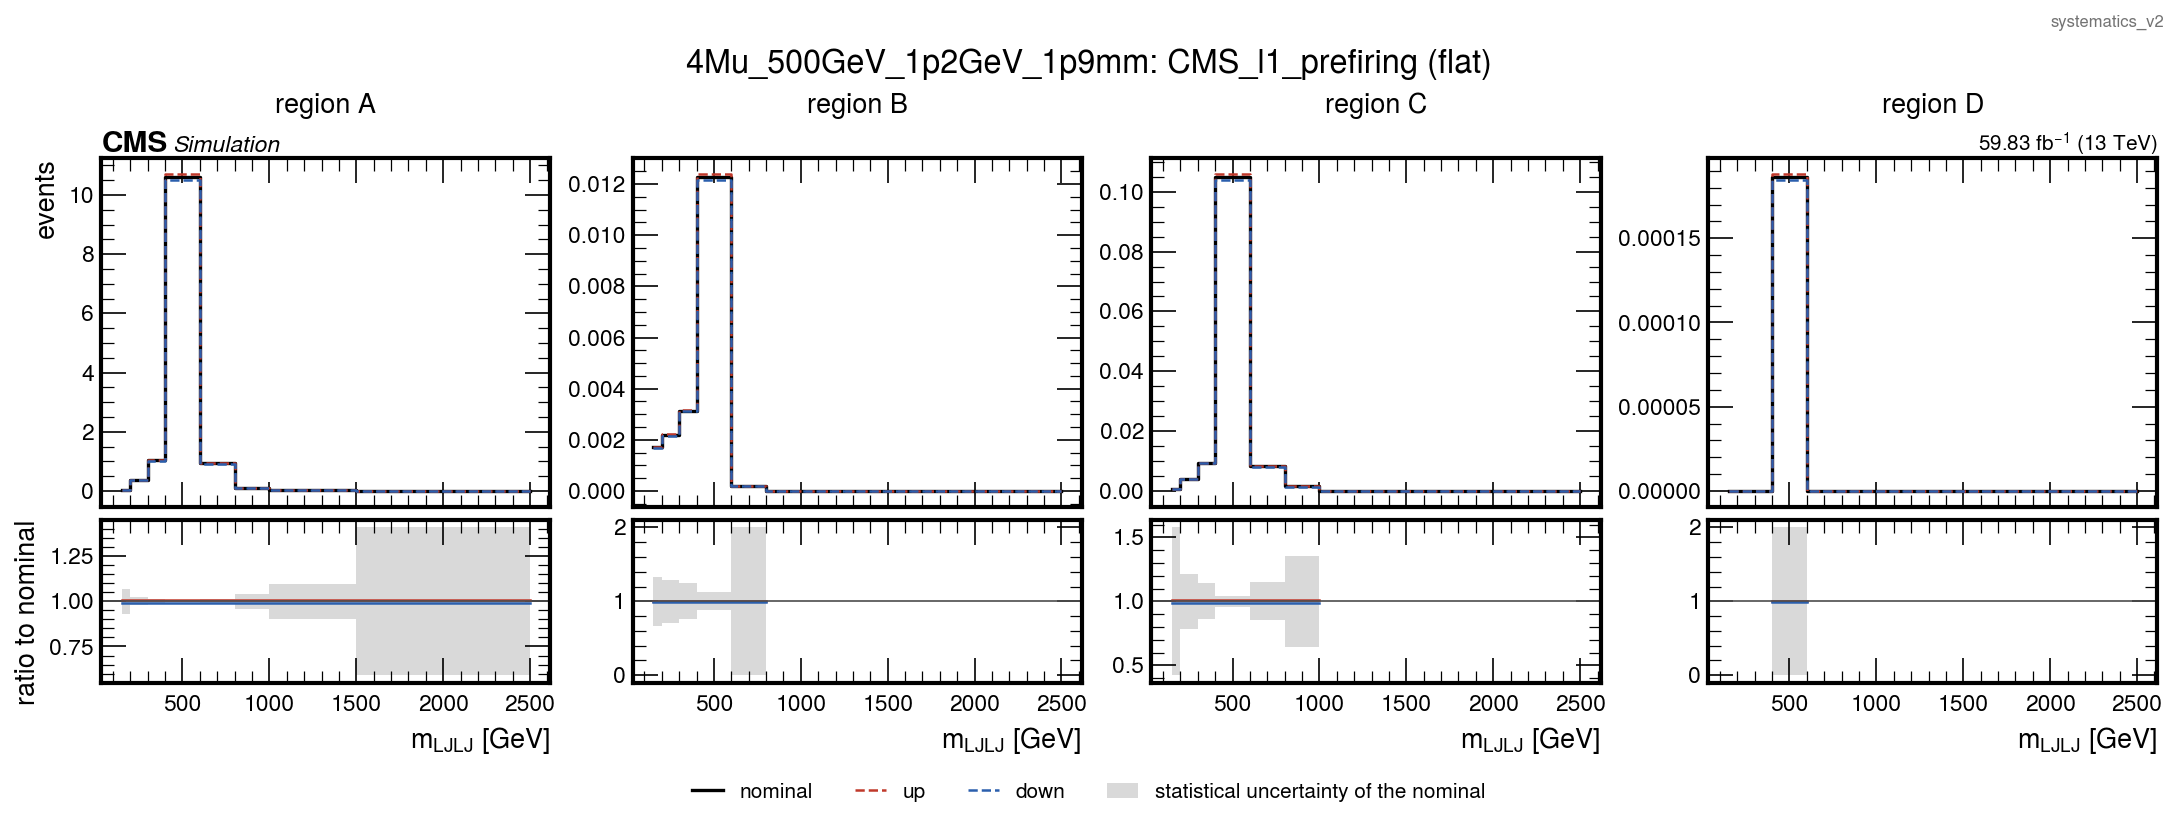

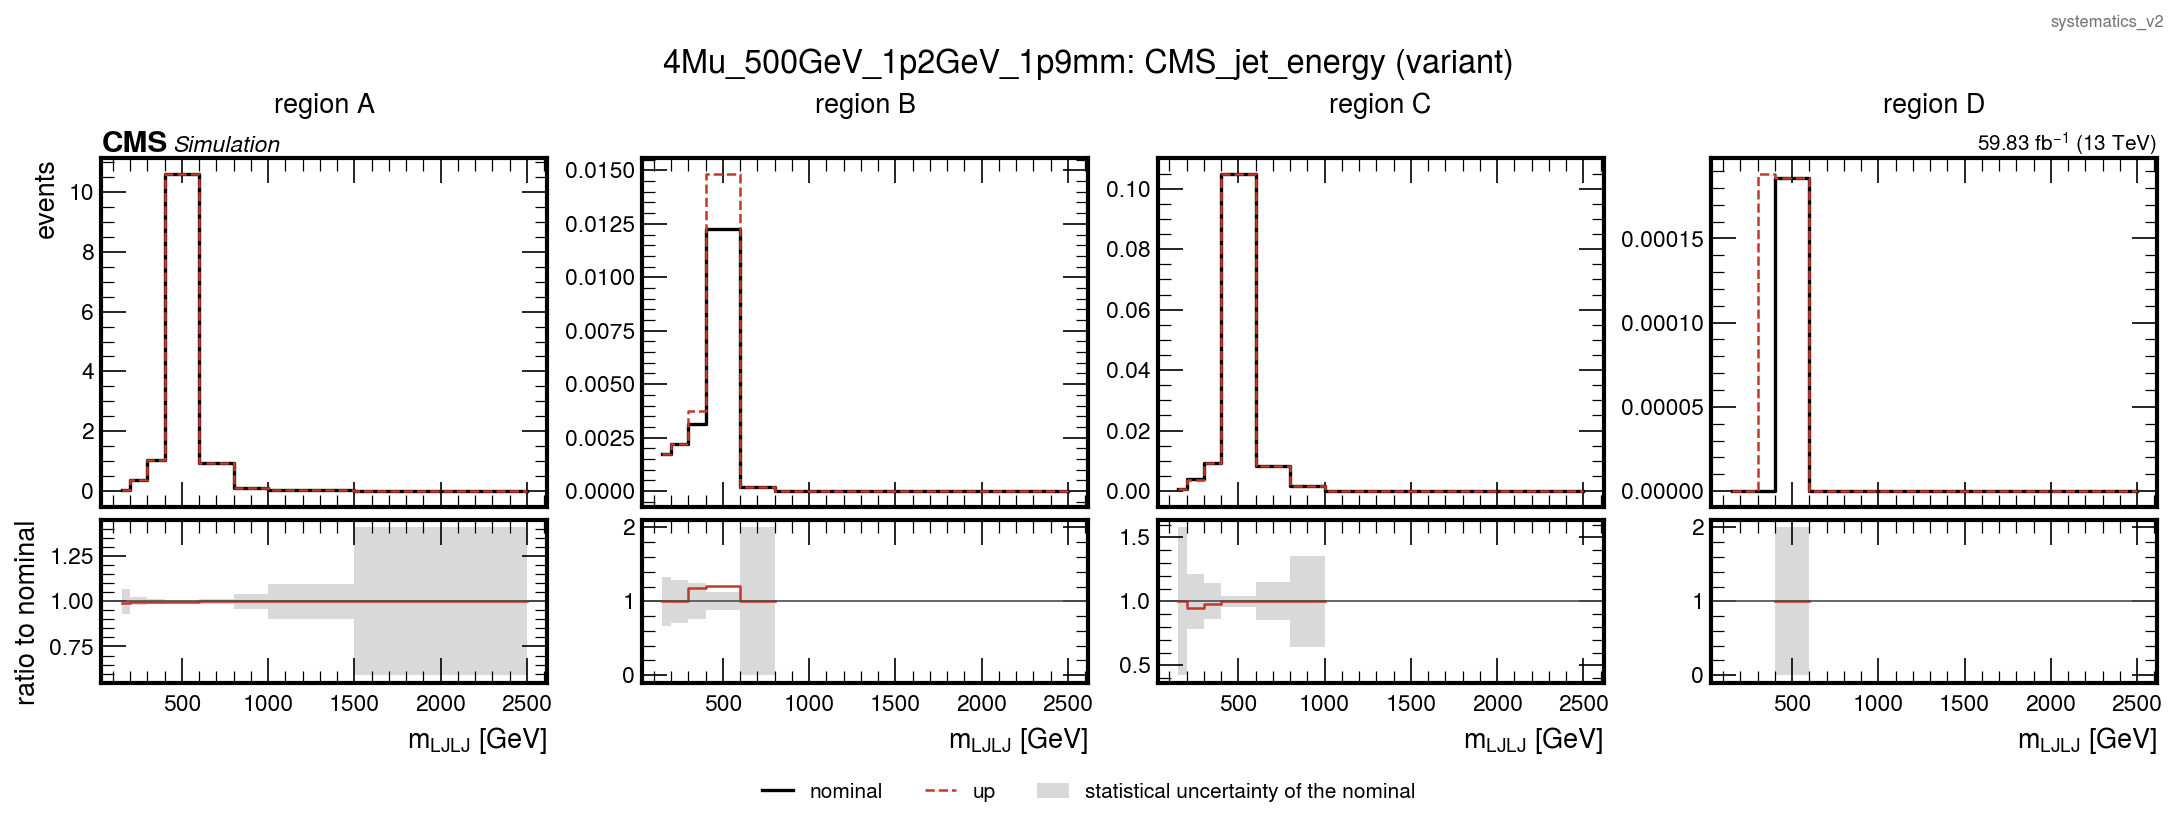

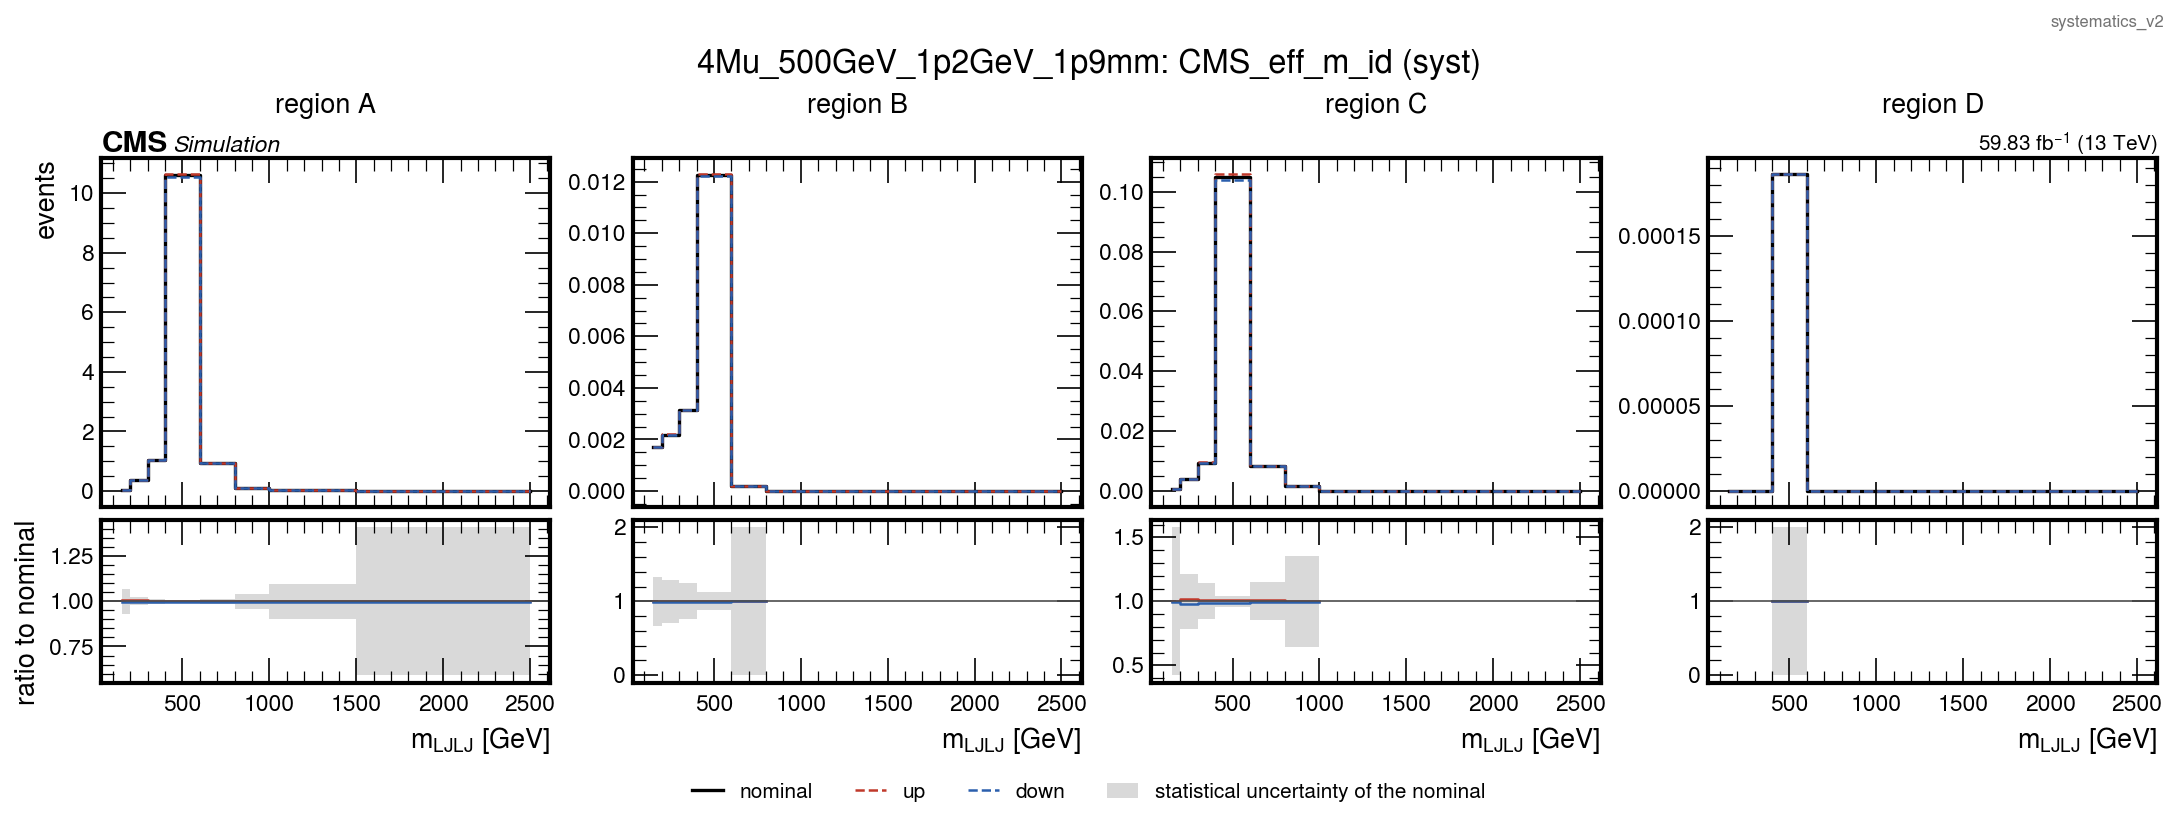

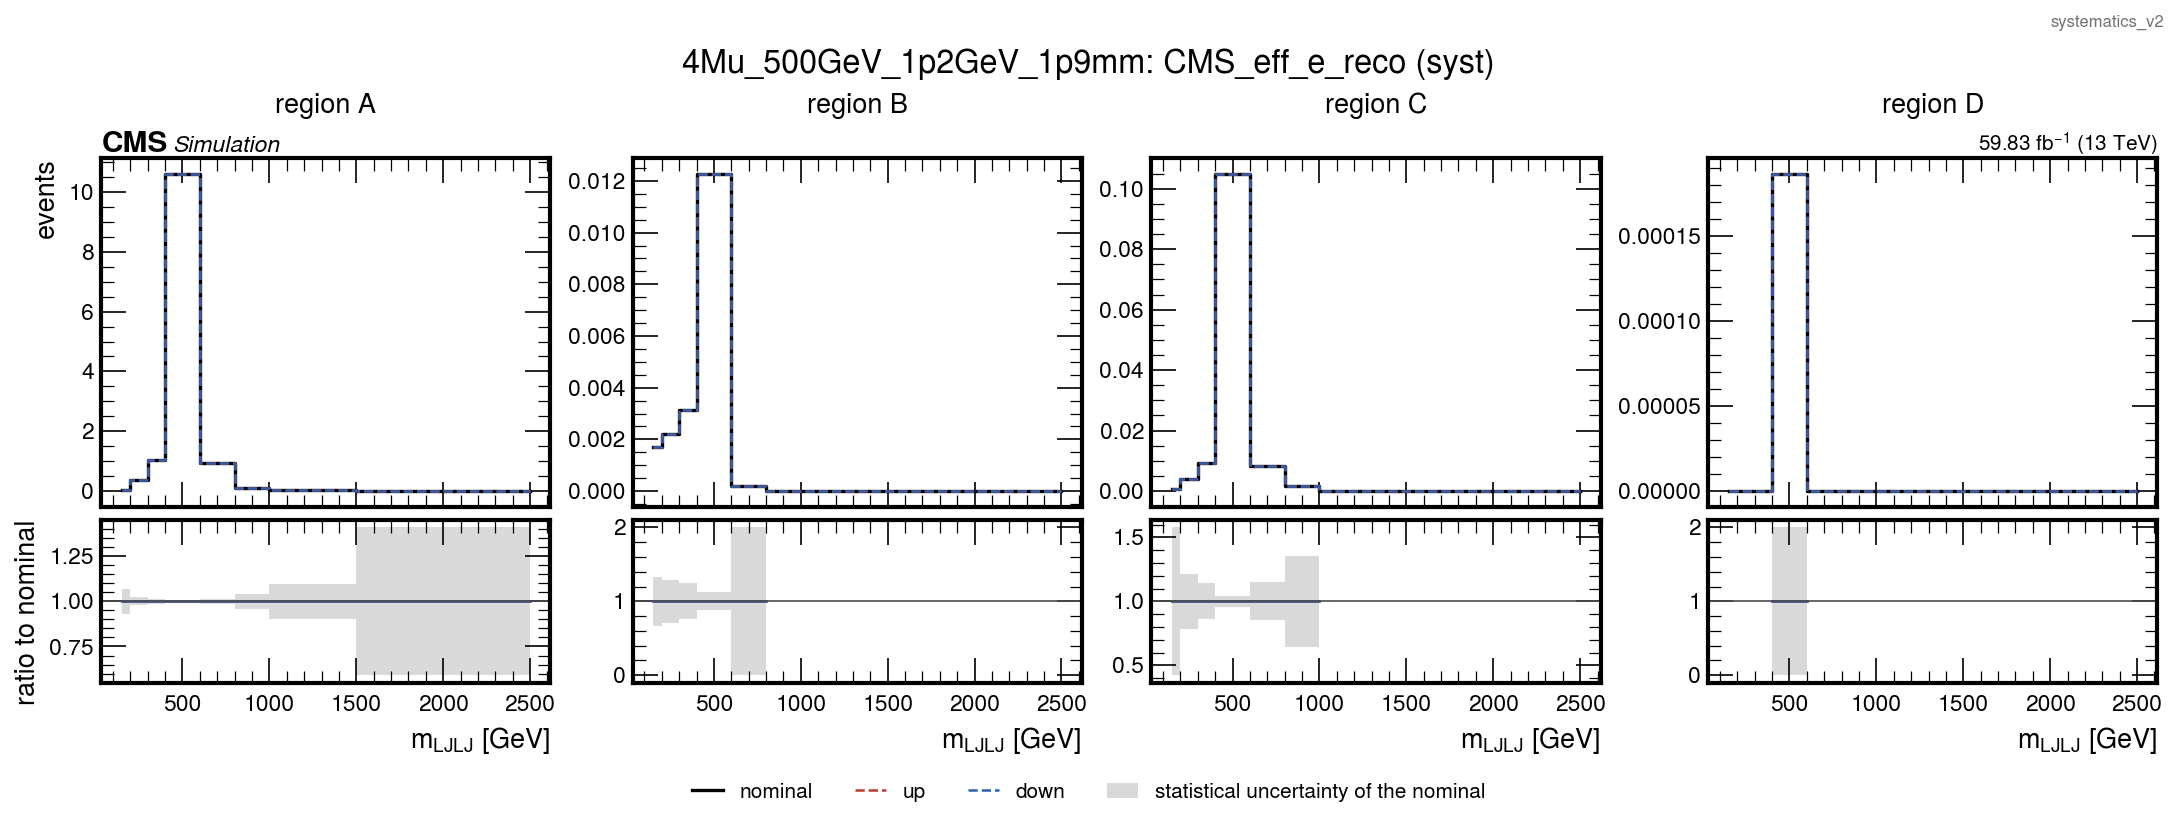

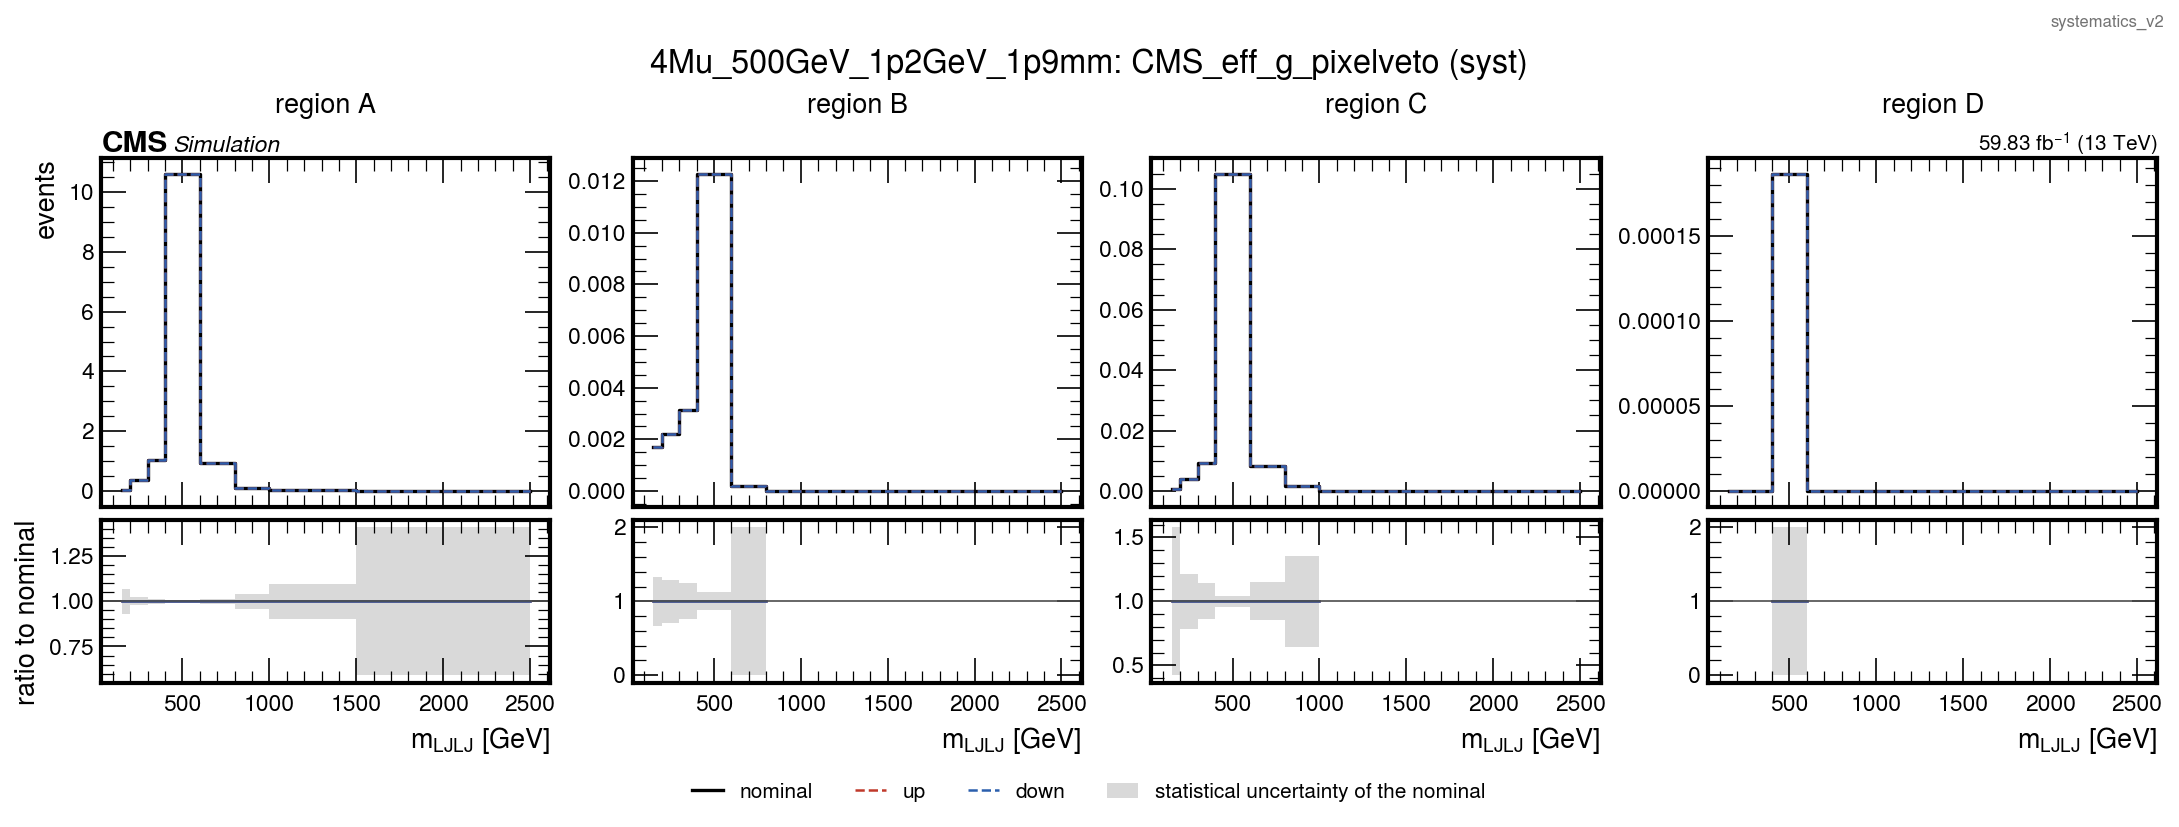

In [2]:
for channel, point in POINTS.items():
    out = dt.read_coffea(f"{INPUT_DIR}/{point}.coffea")[point]
    nominal = sysstudy.st.region_shapes_6d(out, channel, sysstudy.PLANE, point,
                                           selection=sysstudy.WORKING_POINTS[channel])
    for nuisance, entry in REGISTRY.items():
        varied = sysstudy.variations(out, point, channel, entry, nominal)
        show(pt.variation_plot(nominal, varied, FIGURES, CAMPAIGN, f"templates_{nuisance}_{point}",
                               title=f"{point}: {nuisance} ({next(iter(entry))})"))

**Interpretation (run of 2026-11-16: background from regions B, C and D in data, integrated
estimate, seven systematics, 4mu at most 3 pixel hits).**
Both points put their signal in the 400 to 600 GeV bin of region A, with a few percent or less in
B, C and D.

* Luminosity and prefiring scale every bin by the same factor, by construction.
* Pileup changes region A by less than 1% in the populated bins, flat within the statistical
  band; its larger excursions are in bins and regions that hold almost no signal.
* The jet energy variation moves signal from region A to region B, as a few lepton jets cross the
  isolation cut: region A loses about 0.5% (2Mu2E) and 0.1% (4Mu), and the small yield in B
  grows by 15 to 16%. Within region A the change is flat.
* The three scale factors change every region by the same few tenths of a percent, flat in
  $m_{LJLJ}$: the muon identification in both final states, the electron reconstruction and the
  photon pixel veto in 2Mu2E only.

**For the analysis:** all seven act on the normalisation of each region, which is what one
log-normal value per region in the cards describes; none needs a shape uncertainty in
$m_{LJLJ}$. The migration from A to B is carried by the region-dependent values of
`CMS_jet_energy`.

## 2. Size across the signal grid

In region A, at every point of the limit grid: the size of each systematic that varies from
point to point (half the difference of up and down for an asymmetric one), and the
statistical uncertainty of the simulated signal, which the cards carry as the `mcstat`
rows. A flat entry has the same size everywhere and is only listed.

lumi_13TeV: 0.83% at every point
CMS_l1_prefiring: 1.00% at every point


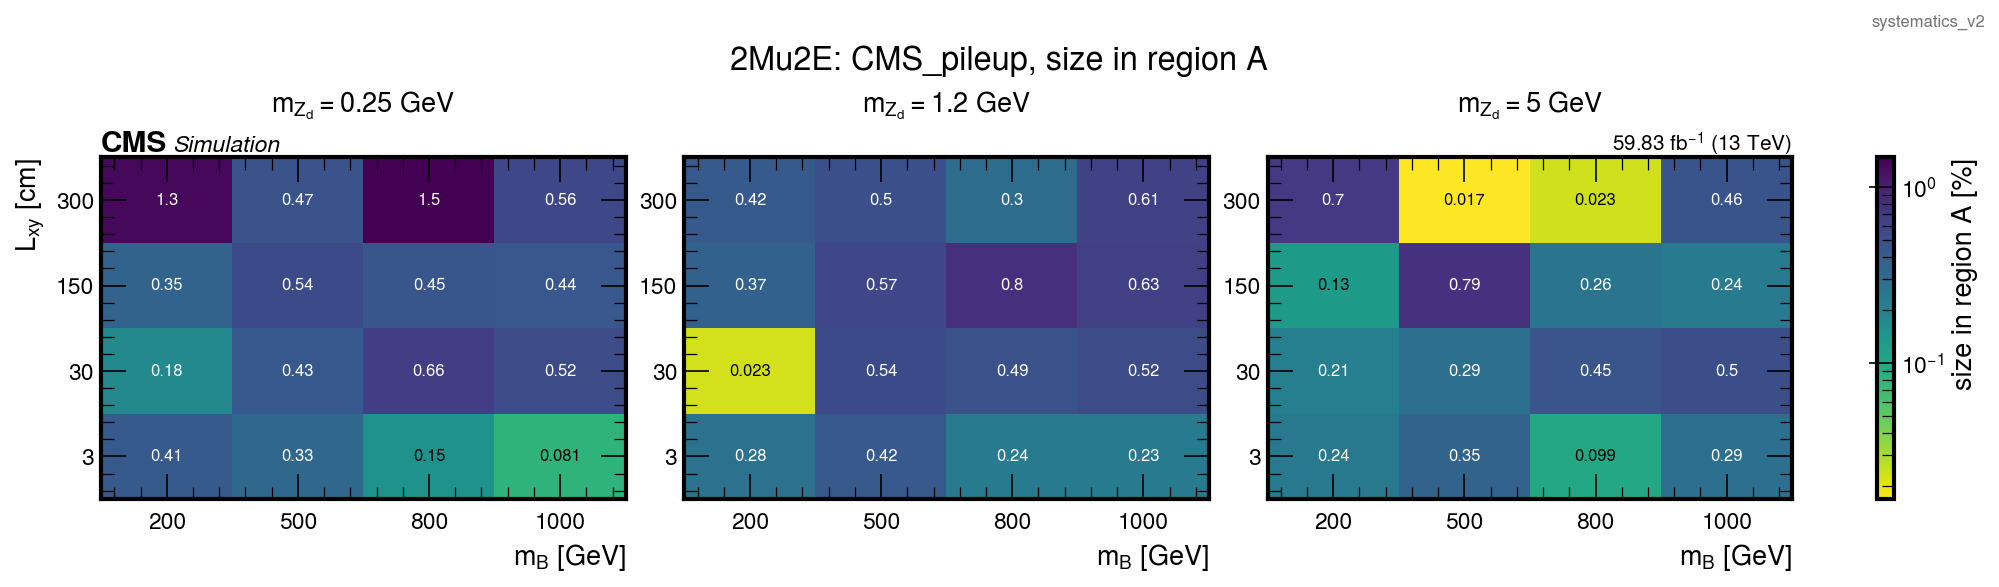

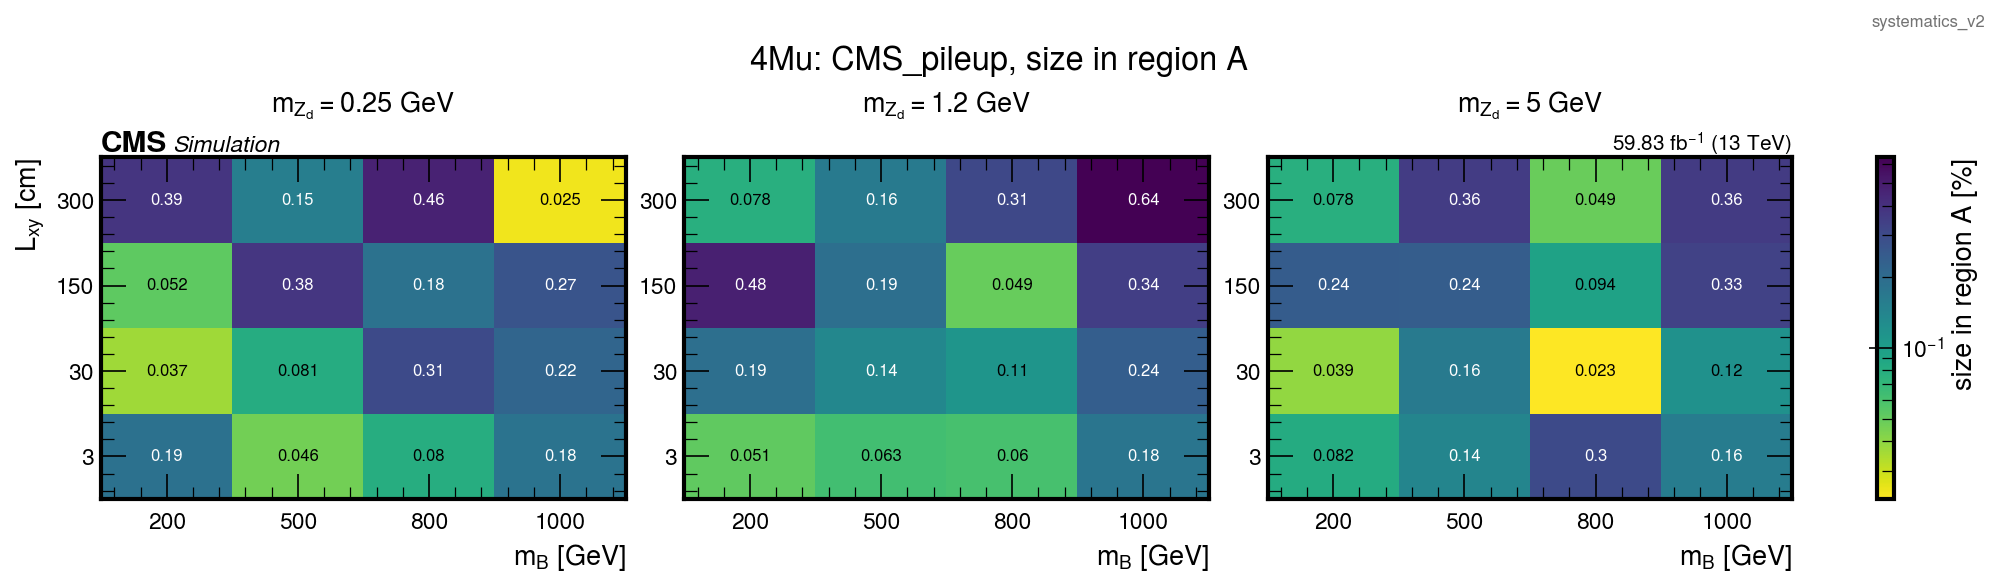

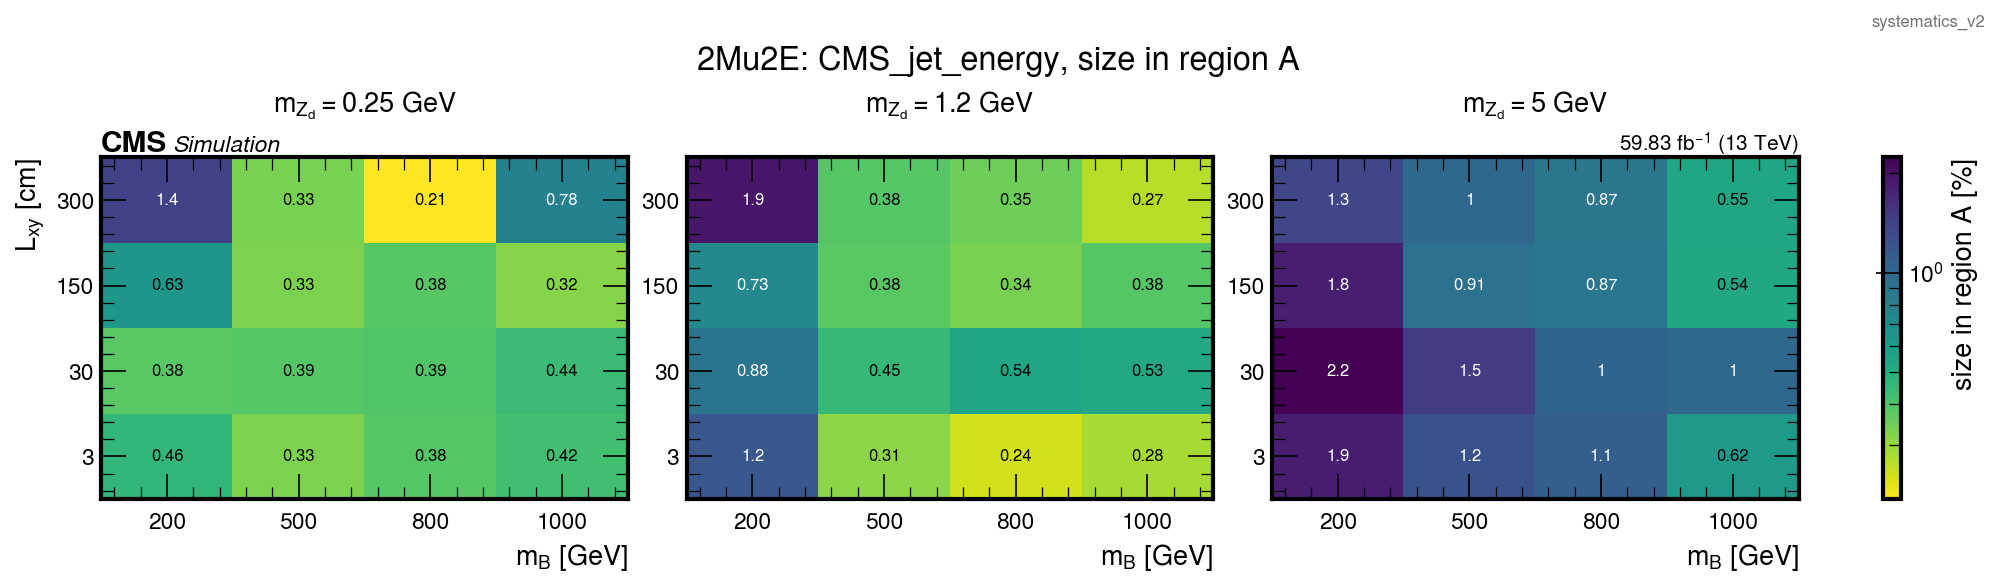

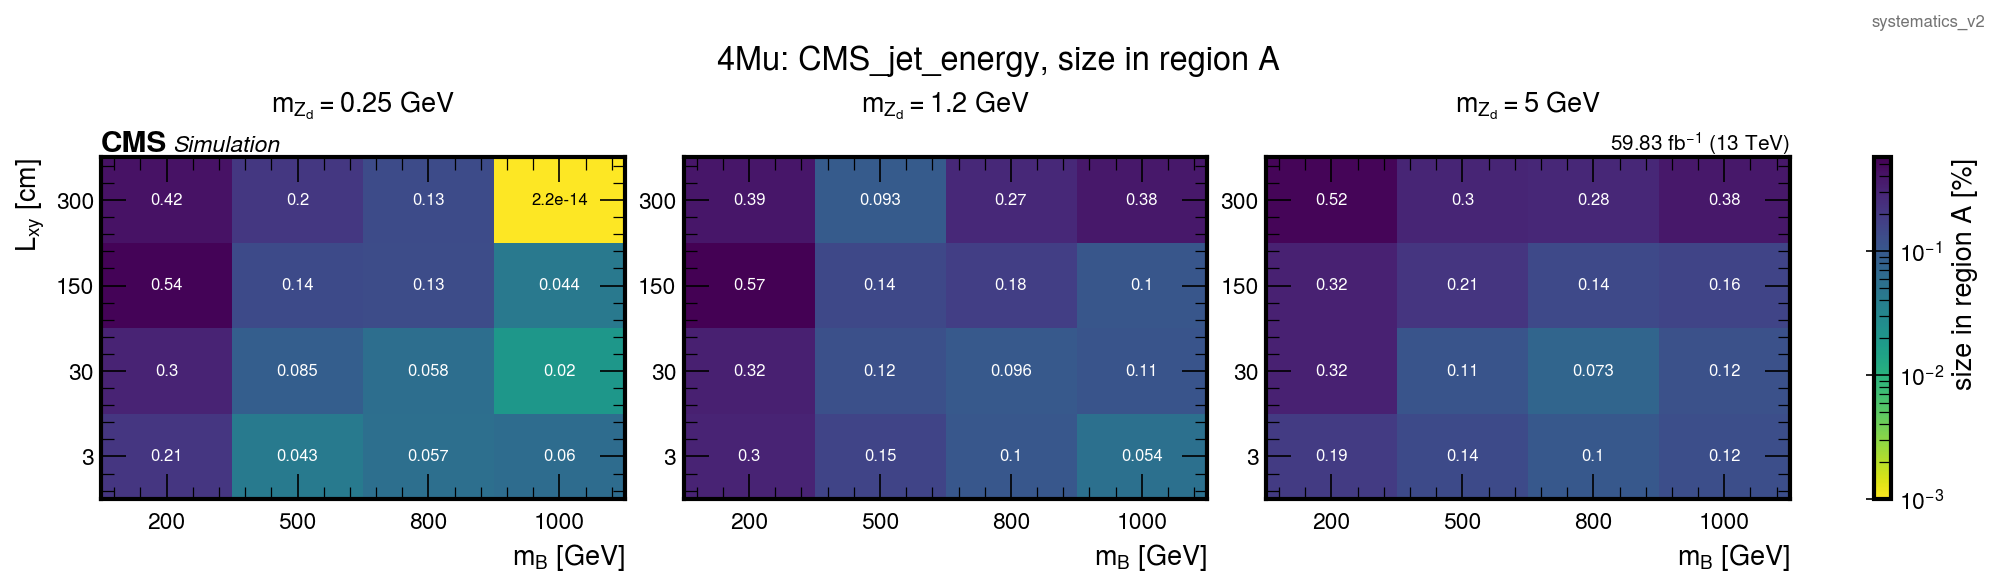

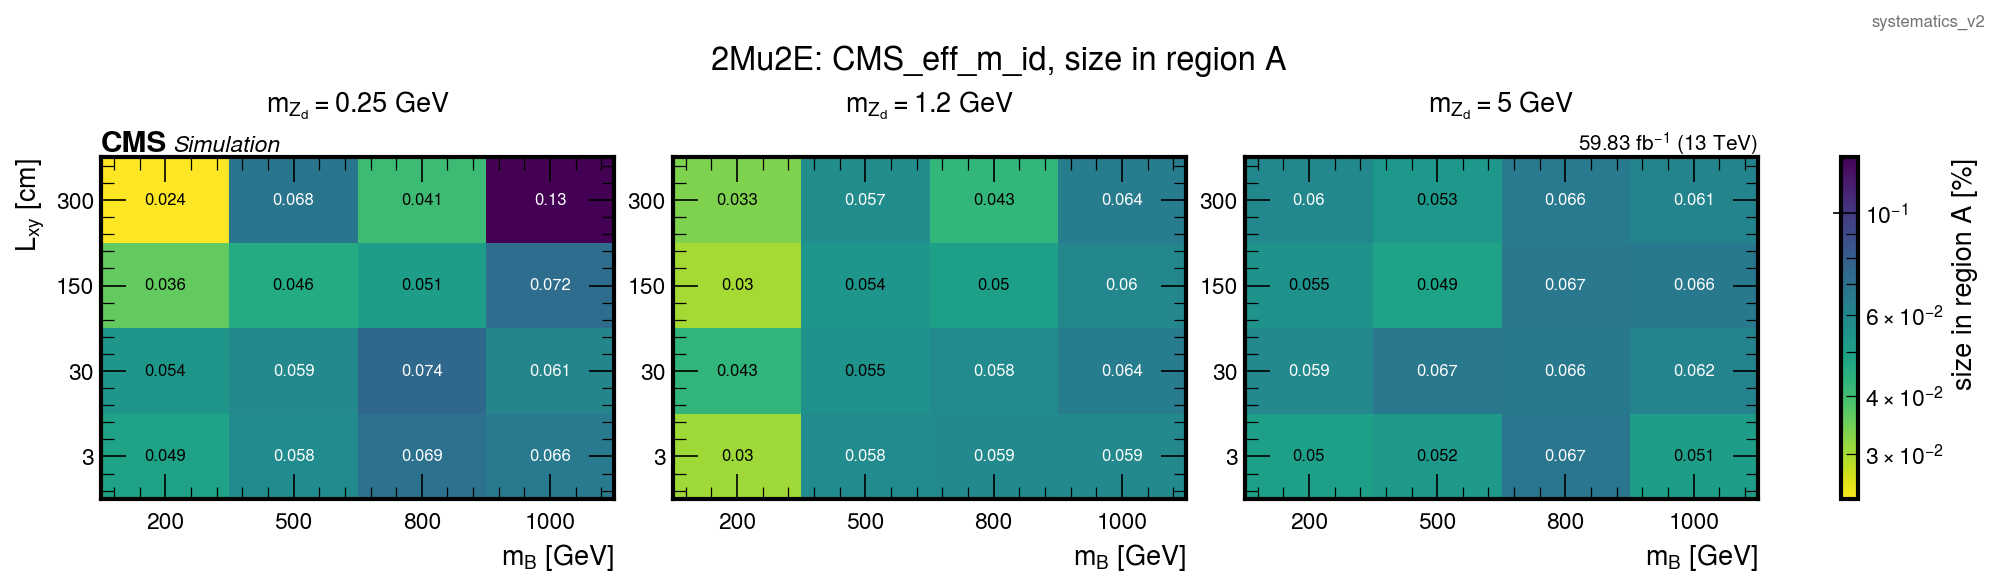

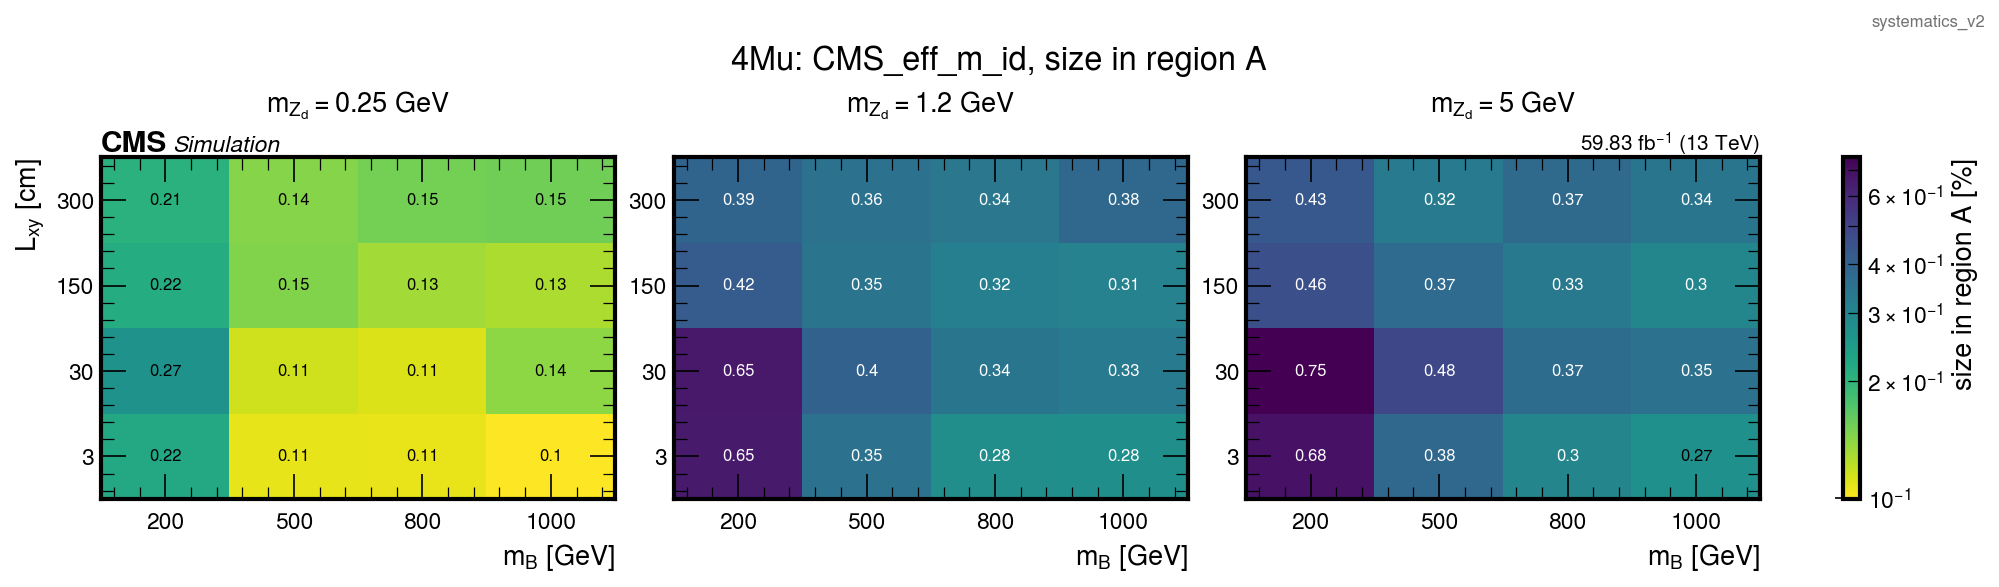

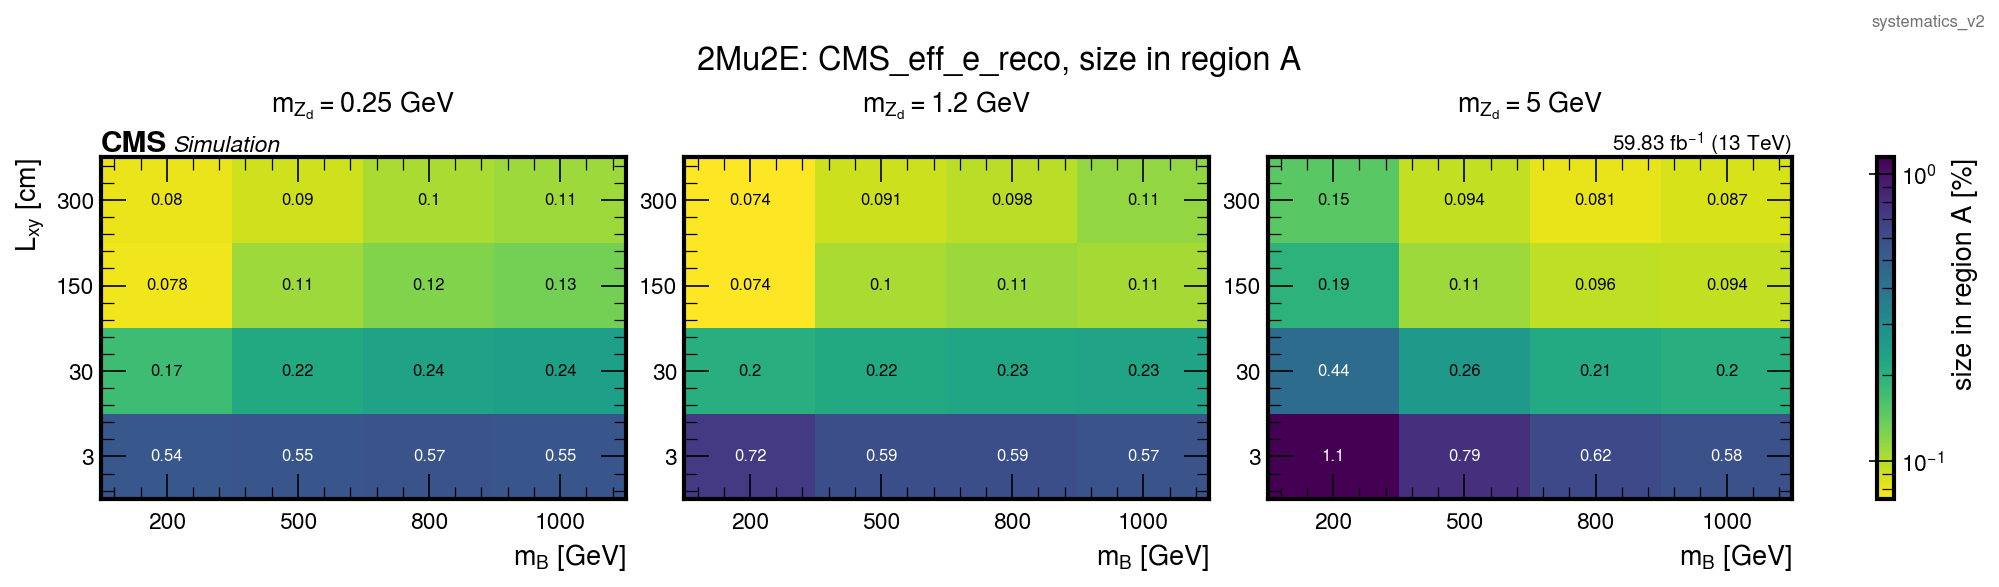

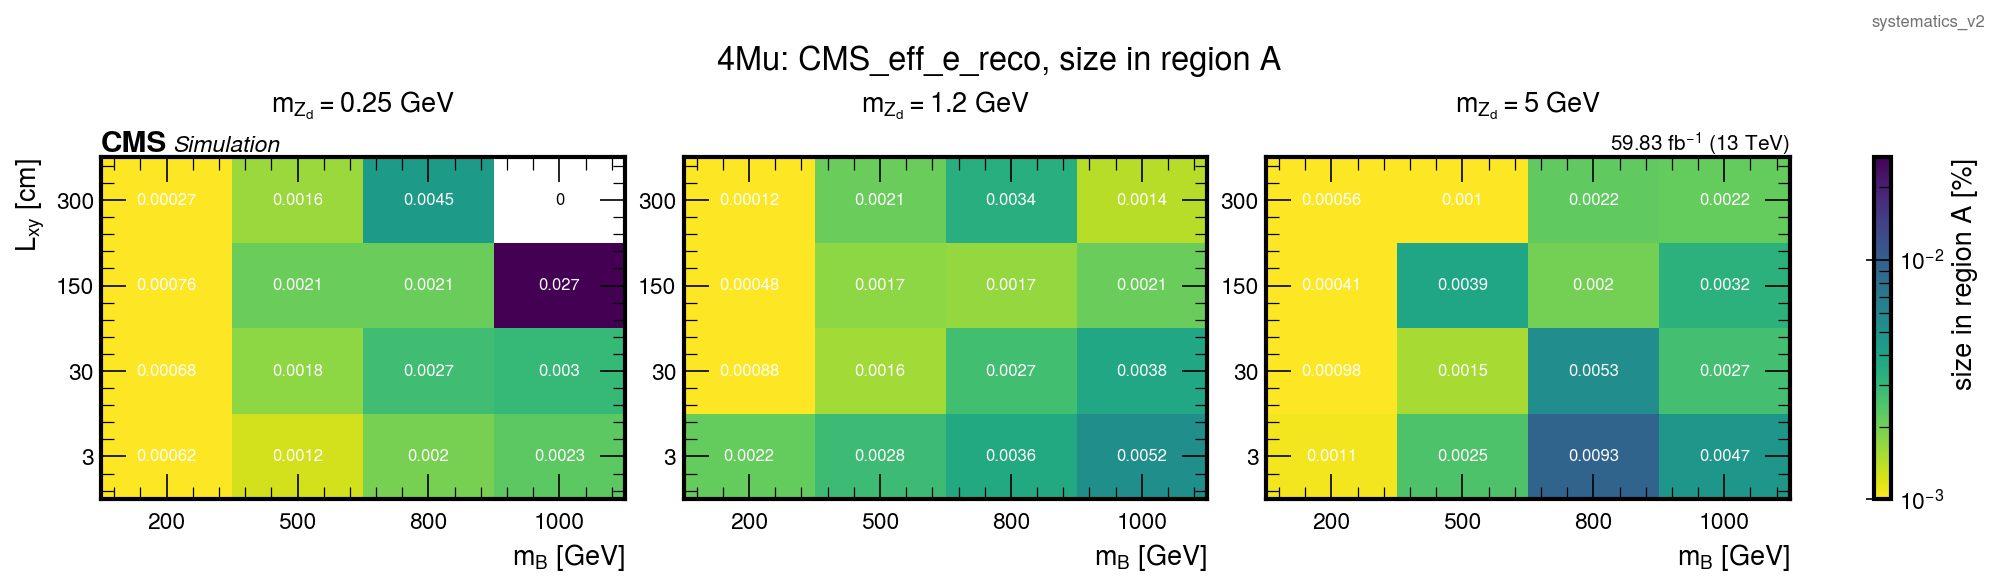

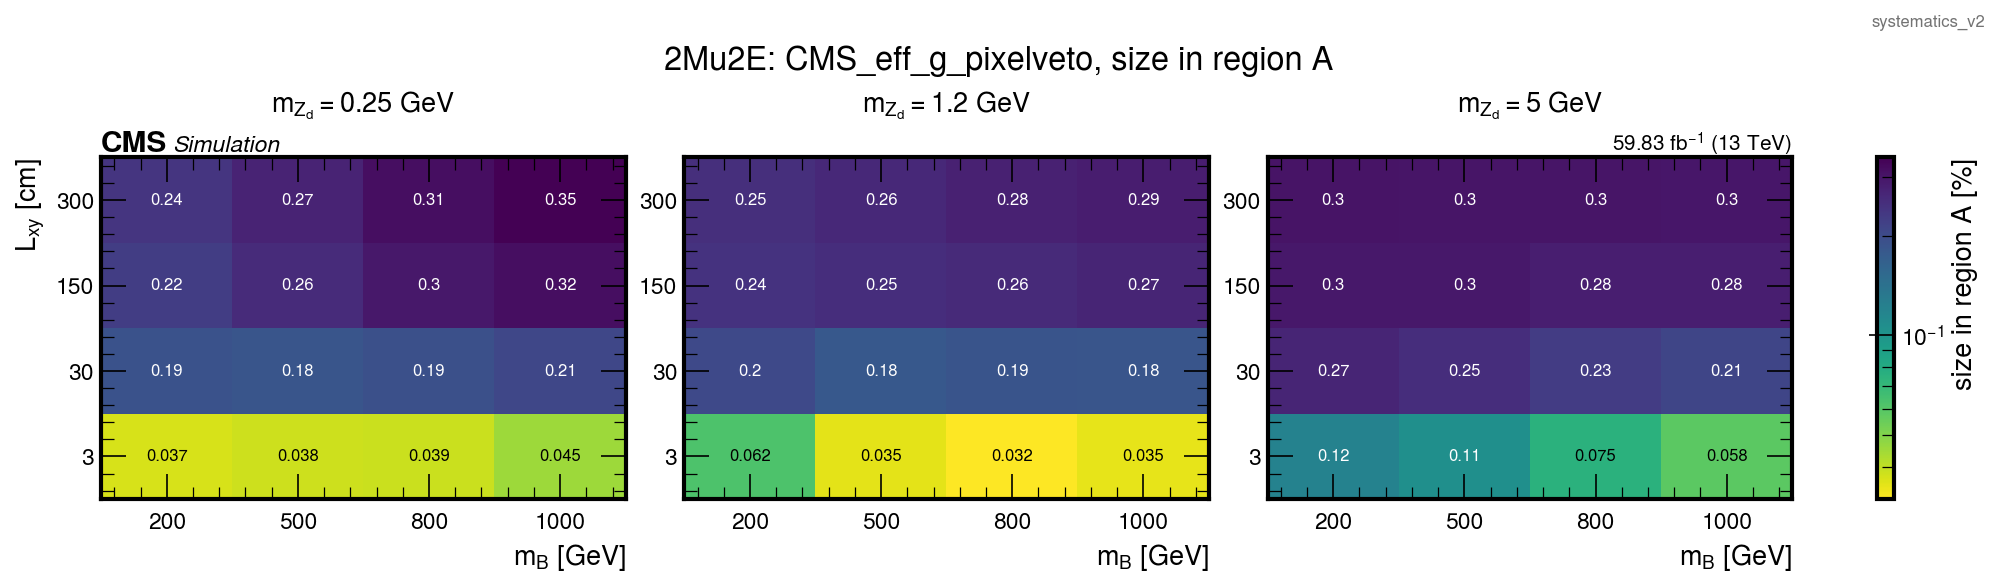

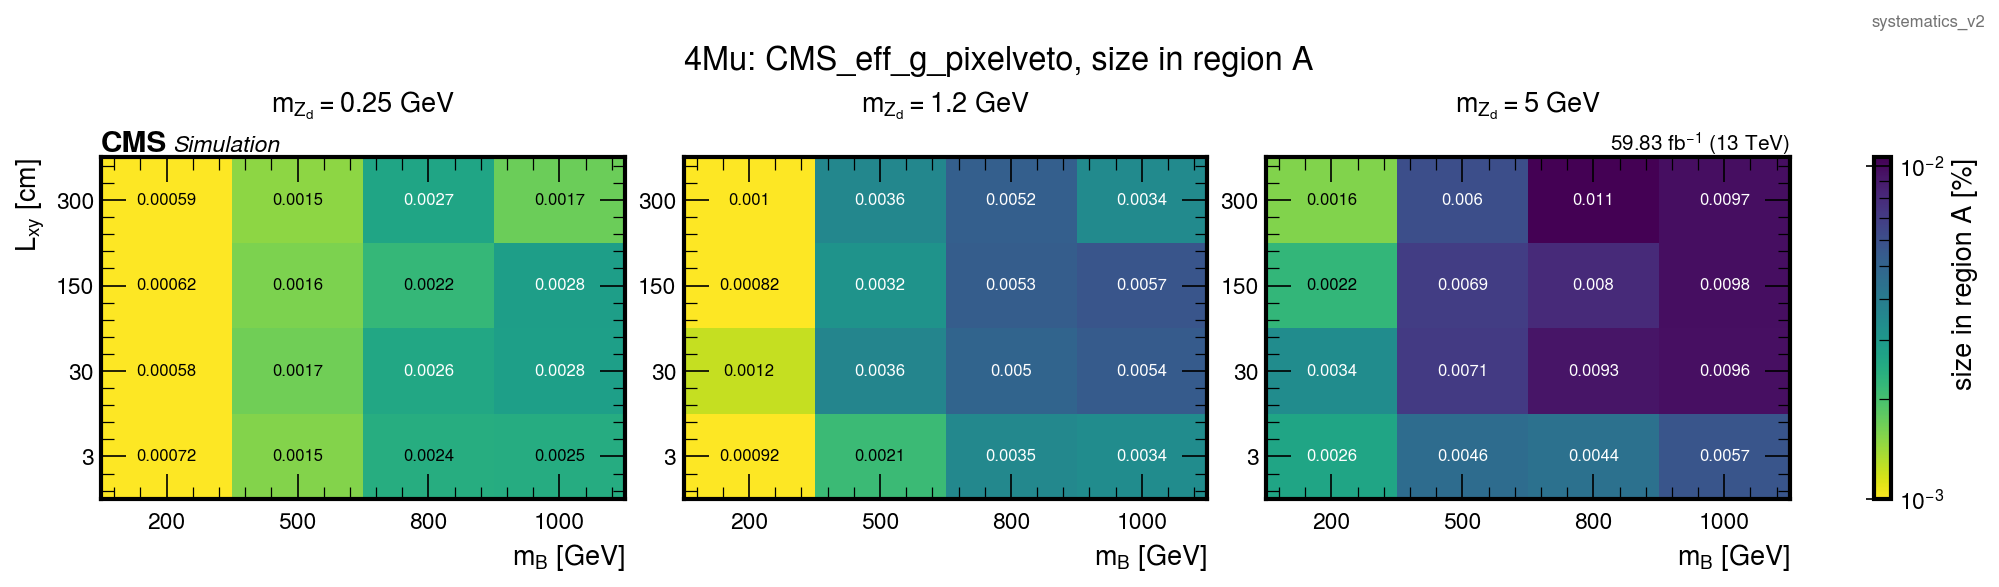

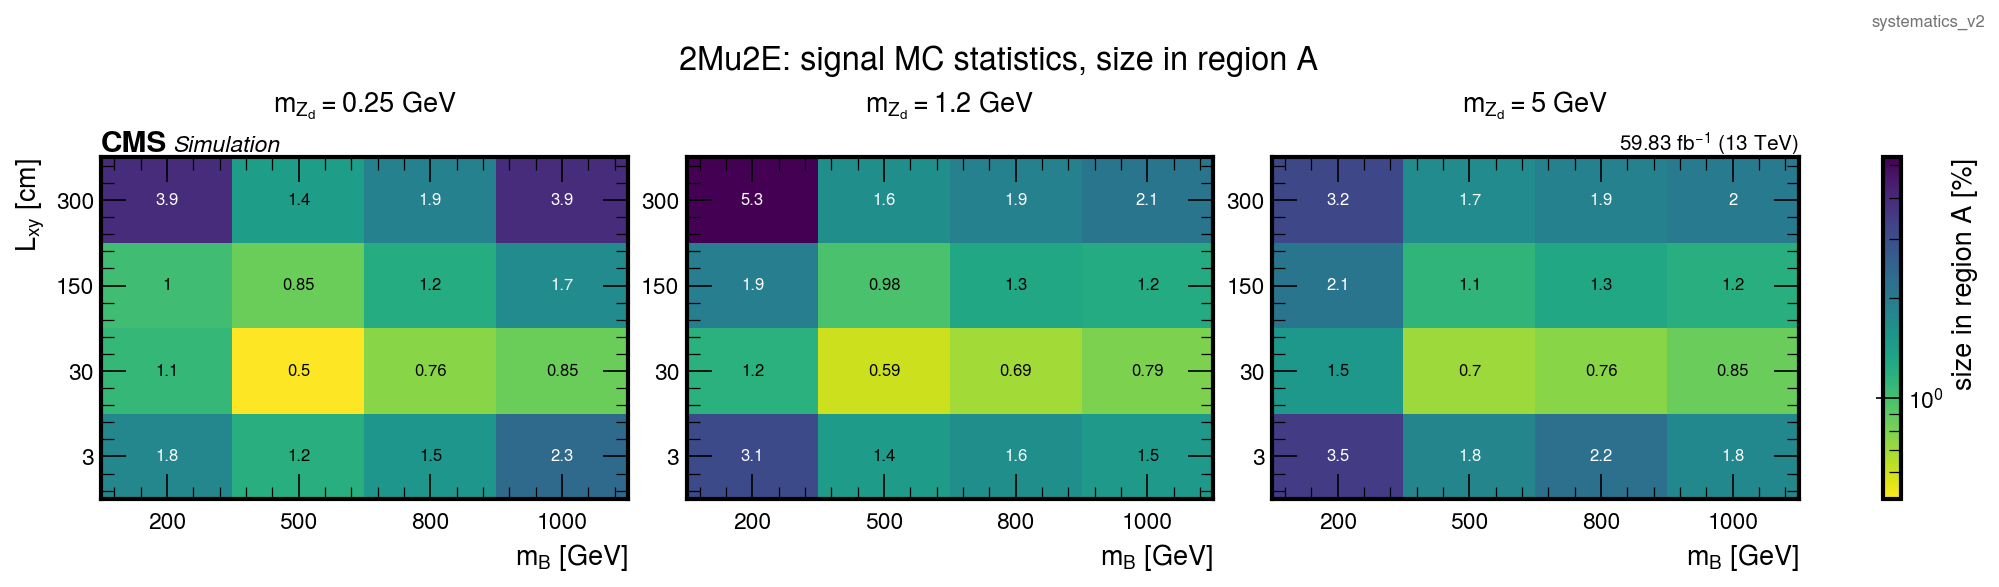

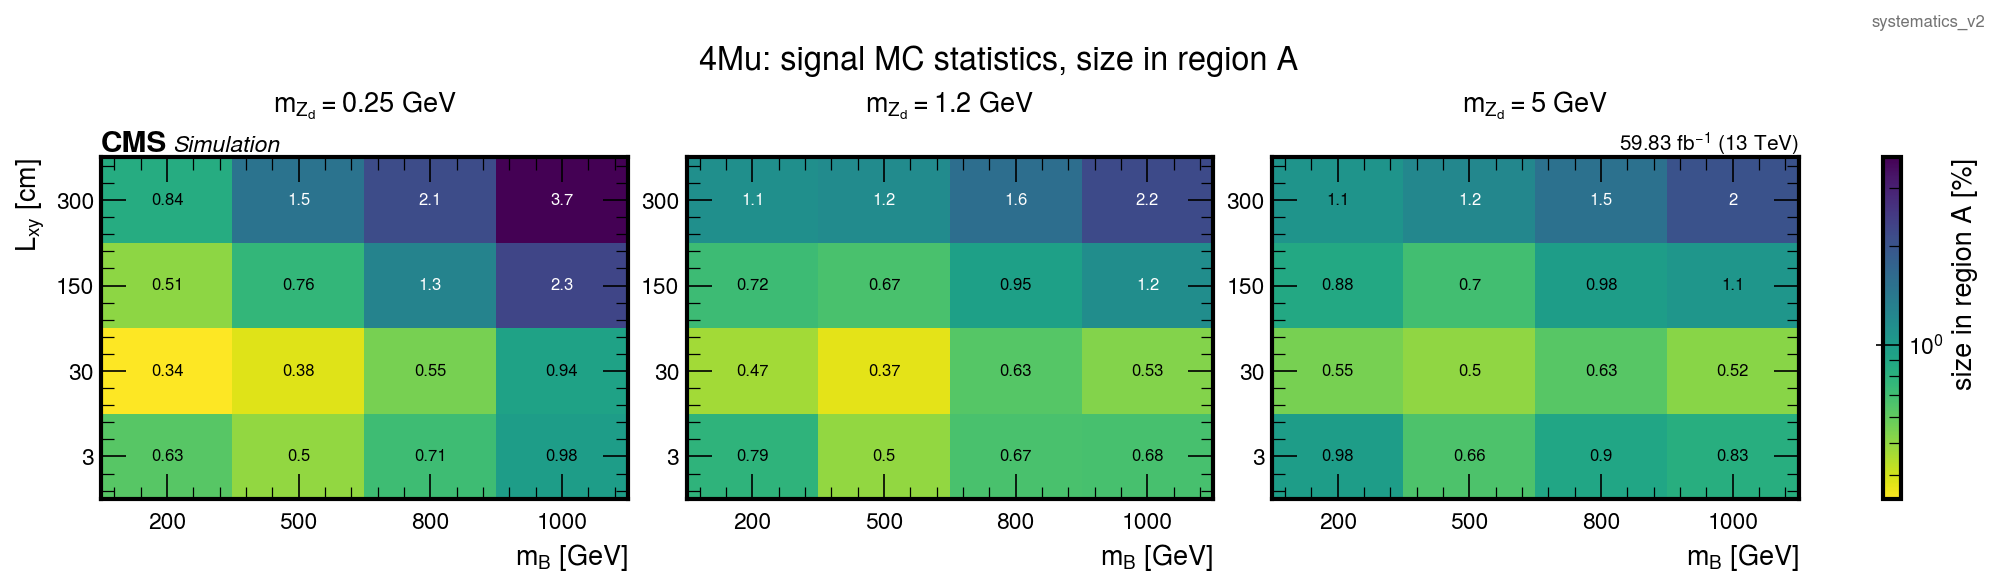

In [3]:
maps = {}
for nuisance, entry in REGISTRY.items():
    if "flat" in entry:
        print(f"{nuisance}: {100 * entry['flat']:.2f}% at every point")
    else:
        maps[nuisance] = {s: 100 * sysstudy.kappa_size(KAPPAS[s][nuisance]["A"]) for s in LIMIT}

payloads = {}
for channel in POINTS:
    with fsspec.open(f"{LIMITS_DIR}/inputs/with/shapes_{channel}.json") as f:
        payloads[channel] = json.load(f)
channel_of = {s: sysstudy.FINAL_STATE_CHANNEL[s.split("_")[0]] for s in LIMIT}
maps["signal MC statistics"] = {s: 100 * sysstudy.signal_mc_stat(payloads[channel_of[s]], s, channel_of[s])
                                for s in LIMIT}

for label, sizes in maps.items():
    rows = [dict(pt.parse_point(s), signal=s, size=v) for s, v in sizes.items()]
    for final_state in ("2Mu2E", "4Mu"):
        show(pt.exclusion_map(rows, final_state, FIGURES, CAMPAIGN, name=f"size_{label.replace(' ', '_')}_{final_state}",
                              field="size", label="size in region A [%]", outline_below=None,
                              title=f"{final_state}: {label}, size in region A"))

**Interpretation.**
* Pileup shows no trend over the grid: 0.02 to 1.5% for 2Mu2E (at most 0.64% for 4Mu), the
  largest values at $L_{xy}$ = 300 cm, where the simulated signal is scarcest. Notebook 01 found
  most of these within twice their statistical precision, so the pattern from point to point is
  largely statistical.
* The jet energy has a trend: it grows towards heavy dark photons and light bound states, up to
  2.2% at $m_{Z_d}$ = 5 GeV and $m_B$ = 200 GeV (at most 0.57% for 4Mu). Its size is the fraction
  of the signal that a 10% change of the isolation moves across the cut, so more lepton jets sit
  near the cut there.
* The muon identification is largest for 4Mu at 200 GeV (up to 0.75%), where the muons are
  softest and the SF below 20 GeV has the larger uncertainty. In 2Mu2E the electron
  reconstruction is largest at 3 cm (0.5 to 1.1%) and falls to 0.1% at 150 and 300 cm, while the
  pixel veto does the opposite, from 0.03 to 0.12% at 3 cm to 0.25 to 0.35% at 150 and 300 cm:
  the egamma-type lepton jets of displaced decays are made of photons rather than electrons.
* The statistical uncertainty of the simulated signal is 0.3 to 5.3% in region A (at most 3.7%
  for 4Mu), smallest at 30 cm and largest at 300 cm, where fewer simulated events pass. At many
  points it is the largest uncertainty on the signal.

**For the analysis:** a single pileup value (the flat 1.5% fallback covers every point) would be
a fair simplification, while the jet energy is worth keeping per point. More simulated signal
at the longest lifetimes would reduce the largest signal uncertainty there.

## 3. Impacts

The left panel is the pull of each nuisance, its fitted value against its pre-fit one in
units of the pre-fit uncertainty, with its post-fit uncertainty as the error bar: zero and
one on the Asimov dataset, as in the pull plot of 03_limits. The right panel is the impact:
the shift of the fitted $r$, relative to the fitted value, when the nuisance is fixed one
post-fit standard deviation above (red) or below (blue) its best fit, the largest at the
top. The free background parameters of the ABCD model are left out.

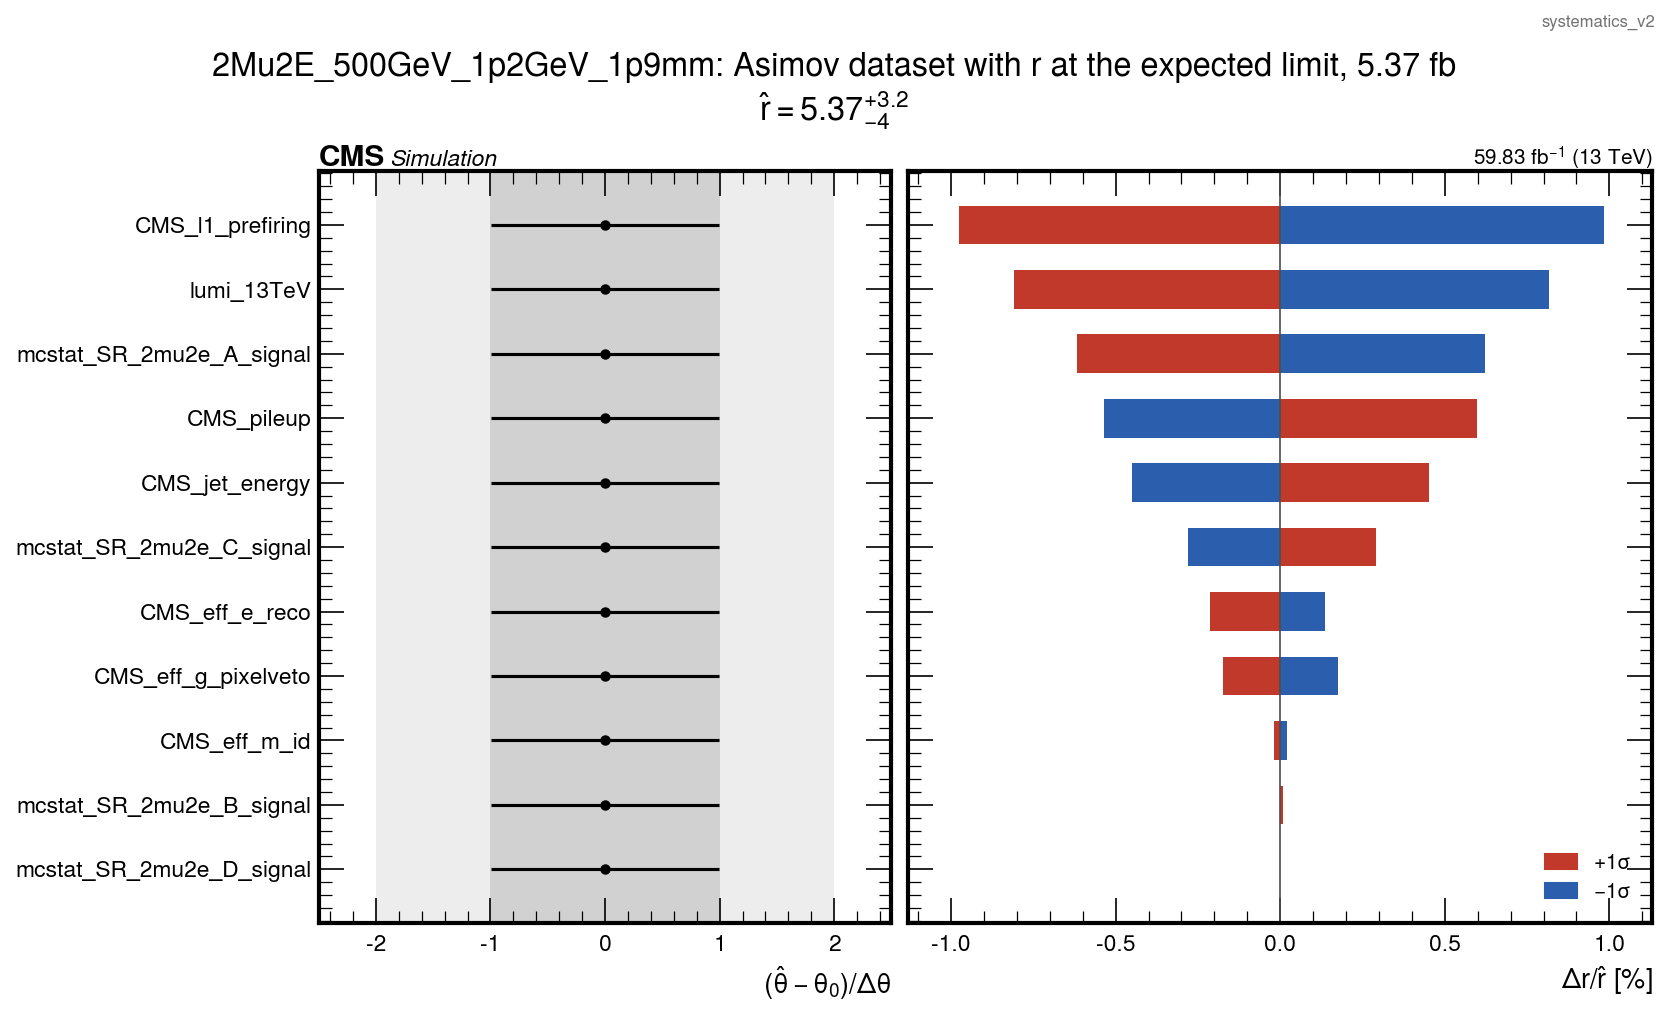

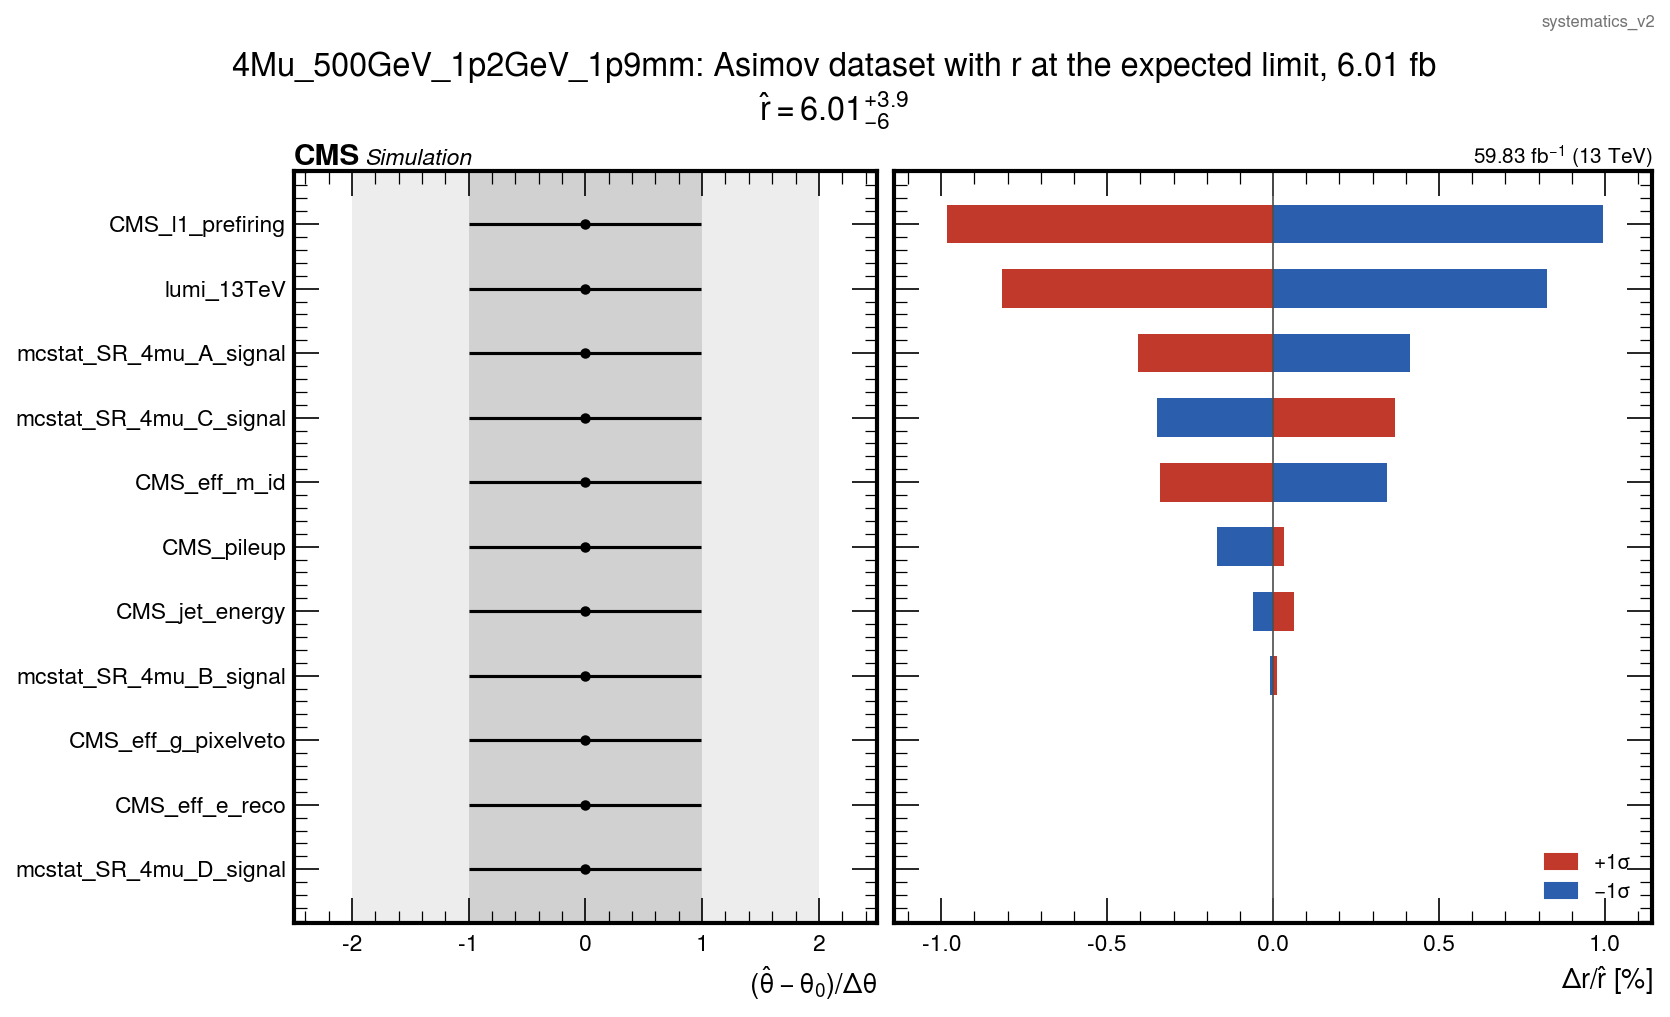

In [4]:
if COMBINE is None:
    raise RuntimeError("Combine is not available here: put `combine` on the PATH or set COMBINE_CMSSW_BASE.")
CARDS = WORK / "cards"
sysstudy.download(f"{LIMITS_DIR}/cards_with_{sysstudy.LIMITS_METHOD}", CARDS)   # the cards with corrections and systematics

for channel, point in POINTS.items():
    outdir = WORK / f"impacts_{point}"
    sysstudy.run_script("run_combine_impacts.py", CARDS / f"datacard_shape_{channel}_{point}.txt",
                        "--outdir", outdir, "--expect-signal", f"{EXPECTED[point]:.6g}", "-j", "8",
                        combine=COMBINE, log=WORK / f"impacts_{point}.log")
    impacts = json.loads((outdir / "impacts.json").read_text())
    show(pt.impact_plot(impacts, FIGURES, CAMPAIGN, f"impacts_{point}",
                        title=f"{point}: Asimov dataset with r at the expected limit, {EXPECTED[point]:.3g} fb"))

**Interpretation.** With the signal at the expected limit, each nuisance moves $\hat r$ by about
its own size: prefiring 1%, luminosity 0.8%, the statistical uncertainty of the signal in region
A 0.6% (2Mu2E) and 0.4% (4Mu), and the others 0.6% or less. The signal statistics of region C now
move $\hat r$ by 0.3 to 0.4%: with the background from data, the signal that leaks into C, a
region of 12 to 19 events, matters a little. A signal normalisation uncertainty is equivalent to
a change of $r$, hence the one-to-one impacts, and the pulls stay at zero with full-size error
bars, as in the pull plot of 03_limits. All impacts are at the 1% level, against a statistical
uncertainty of $r$ of 60 to 100% at the expected limit (+60/−74% for 2Mu2E, +65/−100% for 4Mu).

**For the analysis:** on the fitted signal strength the systematics are negligible next to the
statistics of the control regions. The largest is prefiring, a flat 1% whose DSA-muon part is an
estimate; computing the prefiring of DSA muons (open item 5 of the README) would make it smaller
and per point.

## 4. Limit breakdown

The expected limits of the AN's hypotheses (the limit grid and the shortest lifetime), computed as in 03_limits (to a relative precision of
$10^{-4}$) with nuisances fixed at their nominal values, which is the same as leaving them
out of the cards: each systematic in turn, all of them, and every constrained nuisance
("statistics only", which also fixes the statistical uncertainty of the simulated signal).
The figure shows the 48 points of the limit grid per final state, where the sizes are quoted:
each dot is one signal point (2Mu2E above 4Mu in every row), how much higher, in percent, the
limit with every systematic is than the limit without the nuisances of that row, and the black
ticks are the medians. The table under it gives the median and the largest change for both
sets of points; the figure leaves out the shortest lifetime, whose few large values would hide
the rest.

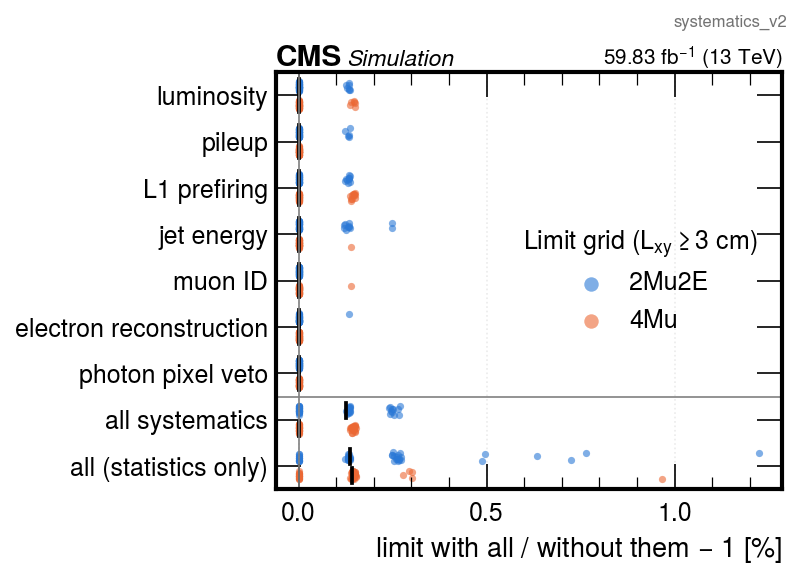

AN hypotheses (60 per final state)      2Mu2E: median, max (%)        4Mu: median, max (%)
  without lumi_13TeV                          0.000      0.137            0.000      0.151
  without CMS_pileup                          0.000      4.688            0.000      0.149
  without CMS_l1_prefiring                    0.000      0.137            0.000      0.151
  without CMS_jet_energy                      0.000      0.435            0.000      0.139
  without CMS_eff_m_id                        0.000      0.000            0.000      0.139
  without CMS_eff_e_reco                      0.000      0.159            0.000      0.000
  without CMS_eff_g_pixelveto                 0.000      0.000            0.000      0.000
  without any systematic                      0.132      4.688            0.000      0.152
  statistics only                             0.252    132.472            0.143      0.967
limit grid (48)                         2Mu2E: median, max (%)        4Mu: median, max (%)

In [5]:
# the hypotheses of the AN's limits: the limit grid and the shortest lifetime
def card_name(s):
    """the datacard of a signal point, in the channel of its final state"""
    return f"datacard_shape_{sysstudy.FINAL_STATE_CHANNEL[s.split('_')[0]]}_{s}.txt"


# (a point without signal in region A has no card)
AN = {s for s in sysstudy.an_hypotheses(KAPPAS) if (CARDS / card_name(s)).exists()}
grid = WORK / "cards_grid"   # their cards, next to their workspaces
grid.mkdir()
for s in AN:
    name = card_name(s)
    (grid / name).symlink_to(CARDS / name)
for workspace in CARDS.glob("param_ws_*.root"):
    (grid / workspace.name).symlink_to(workspace)

variants = sysstudy.freeze_variants(REGISTRY)
limits = {}
for label, frozen in variants.items():
    tag = label.replace(" ", "_")
    sysstudy.run_script("run_combine_limits.py", "--datacards", grid, "--pattern", "datacard_shape_*.txt",
                        "--outdir", WORK / f"limits_{tag}", "-j", "8",
                        f"--extra=--rRelAcc 0.0001 --rAbsAcc 0.00001 --freezeParameters {frozen}",
                        combine=COMBINE, log=WORK / f"limits_{tag}.log", check=False)
    limits[label] = {r["signal"]: r["exp"] for r in pt.as_rows(WORK / f"limits_{tag}" / "limits.csv")}

def breakdown(points):
    """{final state: {label: [change of the limit, %]}} over points"""
    return {final_state: {label: [100 * (EXPECTED[s] / limits[label][s] - 1) for s in sorted(points)
                                  if s.startswith(final_state + "_") and s in limits[label]]
                          for label in variants}
            for final_state in ("2Mu2E", "4Mu")}


# readable row names (a systematic not listed here shows its nuisance name)
NAMES = {"lumi_13TeV": "luminosity", "CMS_pileup": "pileup", "CMS_l1_prefiring": "L1 prefiring",
         "CMS_jet_energy": "jet energy", "CMS_eff_m_id": "muon ID",
         "CMS_eff_e_reco": "electron reconstruction", "CMS_eff_g_pixelveto": "photon pixel veto"}
labels = {f"without {n}": NAMES.get(n, n) for n in REGISTRY}
labels.update({"without any systematic": "all systematics", "statistics only": "all (statistics only)"})
show(pt.breakdown_plot(breakdown(LIMIT), FIGURES, CAMPAIGN, "limit_breakdown",
                       title=r"Limit grid ($L_{xy} \geq 3$ cm)",
                       xlabel="limit with all / without them $-$ 1 [%]",
                       labels=labels, split=len(REGISTRY)))

for name, points in (("AN hypotheses (60 per final state)", AN), ("limit grid (48)", LIMIT)):
    table = breakdown(points)
    print(f"{name:34s}" + "".join(f"{fs + ': median, max (%)':>28s}" for fs in table))
    for label in variants:
        print(f"  {label:32s}" + "".join(f"{np.median(table[fs][label]):17.3f} {max(table[fs][label]):10.3f}"
                                         for fs in table))

**Interpretation.** On the 48 points of the limit grid the systematics barely change the
expected limits: leaving out all seven raises none of them by more than 0.27% (2Mu2E, median
0.13%) and 0.15% (4Mu), and leaving out every constrained nuisance (statistics only) by at most
1.2% and 1.0%. A signal-only uncertainty of about 1% enters an expected limit only at second
order. Most of the few points that move do so by the same amount whichever systematic is left
out, small jumps of the limit calculation.

At the shortest lifetime, which the AN's limits include, fewer simulated 2Mu2E events reach
region A (statistical uncertainty of 4 to 38%, and 22 to 38% at five of the twelve points), and
the values evaluated there are larger and fluctuate: pileup reaches 22% at one point, and leaving
it out moves that limit by 4.7%; leaving out the statistical uncertainty of the simulated signal
moves the limit of the point with 38% by 132%.

**For the analysis:** the expected sensitivity is set by the statistics of the background
estimate, not by these systematics. At the shortest lifetime the per-point values are statistical
fluctuations of the simulated signal; capping them, or taking the pileup value from the
neighbouring lifetimes, would be a sensible choice if those points stay in the limits.

Everything but the copies of the cards goes to EOS, and the local working directory is removed.

In [6]:
for copies in WORK.glob("cards*"):
    shutil.rmtree(copies)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits_data/effects
